<div align="center" style="text-align:center">

<p style="text-align:center;font-size:15px;font-weight:700;color:#283E75;line-height:1.7;margin:0">ĐẠI HỌC QUỐC GIA THÀNH PHỐ HỒ CHÍ MINH<br>TRƯỜNG ĐẠI HỌC KHOA HỌC TỰ NHIÊN<br>KHOA CÔNG NGHỆ THÔNG TIN</p>

<img src="assets/hcmus_logo.png" width="150" style="display:block;margin:12px auto" alt="Logo Trường ĐH Khoa học Tự nhiên">

<p style="text-align:center;font-size:34px;font-weight:700;color:#283E75;margin:8px 0 4px 0">Data Collection &amp; Exploration</p>
<p style="text-align:center;font-size:18px;color:#3B5BA9;margin:0">Notebook 01 · <i>Coffee Quality with Locations of Origin</i> (Kaggle)</p>

<hr style="border:0;border-top:3px solid #283E75;width:60%;margin:12px auto">

<p style="text-align:center;font-size:17px;font-weight:700;margin:4px 0">CSC17104 — Programming for Data Science</p>
<p style="text-align:center;font-size:15px;margin:0">Đồ án cuối kỳ</p>

<hr style="border:0;border-top:3px solid #283E75;width:60%;margin:12px auto">

<table style="font-size:15px;margin:6px auto 0 auto">
<tr style="background-color:#283E75;color:#ffffff"><th style="padding:6px 14px">MSSV</th><th style="padding:6px 14px">Họ tên</th><th style="padding:6px 14px">Phụ trách</th></tr>
<tr><td style="padding:6px 14px">24120053</td><td style="padding:6px 14px">Đặng Ngọc Hoàng</td><td style="padding:6px 14px">3.1 Data collection</td></tr>
<tr style="background-color:#EEF3FB"><td style="padding:6px 14px">23120361</td><td style="padding:6px 14px">Đào Đức Thịnh</td><td style="padding:6px 14px">3.2.1 Overview · 3.2.2 Numerical · 3.2.4 Missing</td></tr>
<tr><td style="padding:6px 14px">24120311</td><td style="padding:6px 14px">Nguyễn Mai Tùng Hiếu</td><td style="padding:6px 14px">3.2.3 Categorical · 3.2.5 Relationships · 3.2.6 Summary</td></tr>
</table>

</div>

<br>

<div style="background-color:#EEF3FB;border:1px solid #C9D6EE;border-radius:8px;padding:12px 22px;font-size:15.5px;line-height:1.65">

<b style="color:#283E75;font-size:17px;letter-spacing:1px">MỤC LỤC</b>

| <span style="color:#283E75">**0 · Môi trường**</span> | <span style="color:#283E75">**3.1 · Data collection**</span> | <span style="color:#283E75">**3.2 · Data exploration**</span> |
|:---|:---|:---|
| Kiểm tra env | Đọc dữ liệu | 3.2.1 Overview |
| Import thư viện | 3.1.1 Subject · 3.1.2 Source | 3.2.2 Numerical columns |
| | 3.1.3 License · 3.1.4 Collection method | 3.2.3 Categorical columns |
| | 3.1.5 Motivation | 3.2.4 Missing data |
| | 3.1.6 Các file dữ liệu | 3.2.5 Relationships · 3.2.6 Summary |

</div>

<div style="background-color:#283E75;color:#ffffff;padding:14px 24px;border-radius:8px;margin-top:24px">

<span style="font-size:17px;font-weight:700;letter-spacing:3px;color:#E3EBFA">PHẦN 0</span>

## <span style="color:#ffffff">Môi trường code &amp; thư viện</span>

<span style="font-size:15px;color:#DCE6F7">Kiểm tra kernel và phiên bản thư viện khớp với <b>environment.yml</b></span>

</div>

#### <span style="color:#3B5BA9">Notebook có chạy đúng env <code>coffee</code> không?</span>

In [1]:
import sys
sys.executable

'/home/hoang/miniconda3/envs/coffee/bin/python'

<span style="color:#5B6B8C;font-size:14px">→ Mong đợi: đường dẫn kết thúc bằng <code>.../envs/coffee/bin/python</code></span>

#### <span style="color:#3B5BA9">Import thư viện</span>

In [2]:
import sys
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

NOTEBOOK_CWD = Path.cwd().resolve()
PROJECT_ROOT = NOTEBOOK_CWD.parent if NOTEBOOK_CWD.name == "notebooks" else NOTEBOOK_CWD
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from src.config import RAW, SCORE_COLS, RANDOM_STATE, add_total_score
from src.labels import CAT_COLS, COUNTRY_ALIASES, group_rare, normalize_labels

pd.set_option("display.max_columns", None) 

%matplotlib inline

In [3]:
import matplotlib

print("numpy     :", np.__version__)
print("pandas    :", pd.__version__)
print("matplotlib:", matplotlib.__version__)

numpy     : 1.26.0
pandas    : 2.1.1
matplotlib: 3.8.0


In [4]:
# TEST
def major_minor(version):
    """'2.1.1' -> '2.1'"""
    return ".".join(version.split(".")[:2])

assert major_minor(np.__version__) == "1.26", f"numpy {np.__version__} khác environment.yml"
assert major_minor(pd.__version__) == "2.1", f"pandas {pd.__version__} khác environment.yml"
assert major_minor(matplotlib.__version__) == "3.8", f"matplotlib {matplotlib.__version__} khác environment.yml"
print("Môi trường OK")

Môi trường OK


<div style="background-color:#283E75;color:#ffffff;padding:14px 24px;border-radius:8px;margin-top:24px">

<span style="font-size:17px;font-weight:700;letter-spacing:3px;color:#E3EBFA">PHẦN 3.1</span>

## <span style="color:#ffffff">Data collection</span>

<span style="font-size:15px;color:#DCE6F7">Dữ liệu nói về gì, lấy từ đâu và được phép dùng thế nào</span>

</div>

### <span style="color:#283E75">▍Đọc dữ liệu</span>

<div style="font-size:15.5px;line-height:1.65">

3 file CSV trong `data/raw/` → `df` (file chính `Coffee_Qlty.csv`) · `df_country` · `df_continent`.

</div>

In [5]:
MAIN_FILE      = RAW / "Coffee_Qlty.csv"
COUNTRY_FILE   = RAW / "Coffee_Qlty_By_Country.csv"
CONTINENT_FILE = RAW / "Coffee_Qlty_By_Continent.csv"

df           = pd.read_csv(MAIN_FILE, keep_default_na=False, na_values=[""])
df_country   = pd.read_csv(COUNTRY_FILE)
df_continent = pd.read_csv(CONTINENT_FILE)

In [6]:
for path, table in [(MAIN_FILE, df), (COUNTRY_FILE, df_country), (CONTINENT_FILE, df_continent)]:
    n_rows, n_cols = table.shape
    print(f"{path.name:<32} {n_rows:>6,} dòng × {n_cols:>3} cột")

Coffee_Qlty.csv                   1,339 dòng ×  22 cột
Coffee_Qlty_By_Country.csv           34 dòng ×  15 cột
Coffee_Qlty_By_Continent.csv          5 dòng ×  15 cột


In [7]:
assert len(sorted(RAW.glob("*.csv"))) == 3, "data/raw/ phải có đúng 3 file CSV"
assert df.shape == (1339, 22), f"df có shape {df.shape}, khác 1.339 × 22"
assert df_country.shape[0] < df.shape[0], "file By_Country phải ít dòng hơn file chính (1 dòng = 1 quốc gia)"
assert df_continent.shape[0] < df_country.shape[0], "số châu lục phải ít hơn số quốc gia"
print("Đọc dữ liệu OK")

Đọc dữ liệu OK


In [8]:
# REC_ID chạy từ 0 nên giá trị lớn nhất = số dòng - 1
print(df["REC_ID"].min(), df["REC_ID"].max(), df["REC_ID"].nunique())

0 1338 1339


<div style="background-color:#FFF7E6;border:1px solid #E8A33D;border-left:6px solid #E8A33D;border-radius:6px;padding:10px 18px;margin:10px 0;font-size:15.5px;line-height:1.65">

<b style="color:#9A5B00;letter-spacing:1px">LƯU Ý</b>

Kaggle hiển thị `REC_ID` từ 0 đến 1338 nên dễ tưởng có 1.338 dòng. Vì `REC_ID` bắt đầu từ 0, dữ liệu thực tế có **1.339 dòng**, không có `REC_ID` trùng.

</div>

### <span style="color:#283E75">▍3.1.1 · Subject</span>

<div style="font-size:15.5px;line-height:1.65">

Mỗi dòng = **một lô cà phê nhân xanh** được chuyên gia *Q Grader* của **Coffee Quality Institute (CQI)** chấm điểm [2].

</div>

<div style="font-size:15.5px;line-height:1.65">

| Khái niệm | Ý nghĩa |
|:---|:---|
| **CQI** | Tổ chức phi lợi nhuận (Mỹ); chứng nhận *Q Grader*, tức chuyên gia nếm cà phê đã qua kiểm tra khứu giác, vị giác [2] |
| **Cupping** | Quy trình nếm chuẩn của SCA: rang nhẹ → xay → ngâm nước nóng → chấm từng thuộc tính thang 0–10 [8] |
| **6 thuộc tính cảm nhận** | Aroma, Flavor, Aftertaste, Acidity, Body, Balance: chấm theo cảm nhận chuyên gia |
| **3 thuộc tính theo cốc** | Uniformity, Clean Cup, Sweetness: 5 cốc × 2 điểm → thường bằng 10 |
| **Specialty** | Total Cup Points (thang 100) ≥ 80 điểm [8] |
| **Moisture** | Độ ẩm hạt; khoảng 10–12% là phù hợp để bảo quản |
| **Defects** | Cat. 1: lỗi nặng (hạt đen, chua) · Cat. 2: lỗi nhẹ (hạt vỡ, sâu đục) |
| **Quakers** | Hạt chưa chín, rang xong có màu nhạt, làm giảm chất lượng vị |

</div>

<div style="background-color:#EEF3FB;border:1px solid #283E75;border-left:6px solid #283E75;border-radius:6px;padding:10px 18px;margin:10px 0;font-size:15.5px;line-height:1.65">

<b style="color:#283E75;letter-spacing:1px">VÌ SAO CẦN <code>total_9</code>?</b>

Dữ liệu chỉ có 9 thuộc tính cảm quan, **không có** *Overall* và *Total Cup Points* → nhóm tự tạo `total_9` = tổng 9 thuộc tính làm thước đo chất lượng tổng hợp.

</div>

In [9]:
#Xem ngẫu nhiên 3 dòng
df.sample(3, random_state=RANDOM_STATE)

,REC_ID,Species,Continent.of.Origin,Country.of.Origin,Harvest.Year,Expiration,Variety,Color,Processing.Method,Aroma,Flavor,Aftertaste,Acidity,Body,Balance,Uniformity,Clean.Cup,Sweetness,Moisture,Quakers,Category.One.Defects,Category.Two.Defects
394,394,Arabica,Asia,Thailand,NaN,04/13/11,Peaberry,NaN,NaN,7.58,7.25,7.50,7.92,7.92,7.42,10.0,10.0,10.0,0.11,0,0,0
881,881,Arabica,Asia,Indonesia,2013.0,05/23/15,Sumatra,Bluish-Green,Semi-washed / Semi-pulped,7.17,7.42,7.33,7.42,7.33,7.42,10.0,10.0,10.0,0.11,0,0,0
358,358,Arabica,Asia,Indonesia,2015.0,09/13/16,Sumatra,Bluish-Green,Semi-washed / Semi-pulped,7.25,7.67,7.58,7.92,7.83,7.58,10.0,10.0,10.0,0.13,0,0,8


In [10]:
#Kiểm tra cột REC_ID có giá trị duy nhất không
n_rows   = len(df)
n_unique = df["REC_ID"].nunique()

print("Số dòng            :", n_rows)
print("Số REC_ID khác nhau:", n_unique)
print("REC_ID duy nhất?   :", df["REC_ID"].is_unique)

Số dòng            : 1339
Số REC_ID khác nhau: 1339
REC_ID duy nhất?   : True


In [11]:
# TEST
assert df["REC_ID"].is_unique, "Có REC_ID bị lặp → một dòng không tương ứng một lô"
assert df["REC_ID"].nunique() == len(df), "Số REC_ID khác số dòng"
assert df["REC_ID"].notna().all(), "Có dòng thiếu REC_ID"
print("REC_ID là duy nhất")

REC_ID là duy nhất


#### <span style="color:#3B5BA9">22 cột chia thành 5 nhóm</span>

<div style="font-size:15.5px;line-height:1.65">

| Nhóm | Các cột | Vai trò |
|:---|:---|:---|
| Định danh | `REC_ID` | Phân biệt lô, không phân tích |
| Xuất xứ | `Species`, `Continent.of.Origin`, `Country.of.Origin` | Biến phân loại để so sánh nhóm |
| Thông tin lô | `Harvest.Year`, `Expiration`, `Variety`, `Color`, `Processing.Method` | Biến phân loại / thời gian |
| Cảm quan | `Aroma` … `Sweetness` (9 cột, thang 0–10) | Kết quả chất lượng → tạo `total_9` |
| Vật lý / lỗi hạt | `Moisture`, `Quakers`, `Category.One.Defects`, `Category.Two.Defects` | Đo trên hạt nhân xanh, trước cupping |

</div>

In [12]:
#Chia nhóm và in bảng
column_groups = {
    "Định danh":        ["REC_ID"],
    "Xuất xứ":          ["Species", "Continent.of.Origin", "Country.of.Origin"],
    "Thông tin lô":     ["Harvest.Year", "Expiration", "Variety", "Color", "Processing.Method"],
    "Cảm quan":         SCORE_COLS,
    "Vật lý / lỗi hạt": ["Moisture", "Quakers", "Category.One.Defects", "Category.Two.Defects"],
}

group_table = pd.DataFrame({
    "Nhóm":    list(column_groups.keys()),
    "Số cột":  [len(cols) for cols in column_groups.values()],
    "Các cột": [", ".join(cols) for cols in column_groups.values()],
})
group_table

,Nhóm,Số cột,Các cột
0,Định danh,1,REC_ID
1,Xuất xứ,3,"Species, Continent.of.Origin, Country.of.Origin"
2,Thông tin lô,5,"Harvest.Year, Expiration, Variety, Color, Proc..."
3,Cảm quan,9,"Aroma, Flavor, Aftertaste, Acidity, Body, Bala..."
4,Vật lý / lỗi hạt,4,"Moisture, Quakers, Category.One.Defects, Categ..."


In [13]:
# TEST
all_grouped = [col for cols in column_groups.values() for col in cols]

assert len(all_grouped) == 22, f"Đang có {len(all_grouped)} cột trong các nhóm, cần 22"
assert len(all_grouped) == len(set(all_grouped)), "Có cột nằm ở 2 nhóm"
assert set(all_grouped) == set(df.columns), (
    f"Thiếu trong nhóm: {set(df.columns) - set(all_grouped)} | "
    f"Không có trong df: {set(all_grouped) - set(df.columns)}"
)
print("Chia nhóm cột OK")

Chia nhóm cột OK


<table style="width:100%;border-collapse:separate;border-spacing:8px 0"><tr><td style="background-color:#EEF3FB;border:1px solid #C9D6EE;border-radius:8px;padding:10px 14px;text-align:center;width:25%"><div style="font-size:24px;font-weight:700;color:#283E75">1.339</div><div style="font-size:13px;color:#4A5568">lô cà phê</div></td><td style="background-color:#EEF3FB;border:1px solid #C9D6EE;border-radius:8px;padding:10px 14px;text-align:center;width:25%"><div style="font-size:24px;font-weight:700;color:#283E75">22</div><div style="font-size:13px;color:#4A5568">cột</div></td><td style="background-color:#EEF3FB;border:1px solid #C9D6EE;border-radius:8px;padding:10px 14px;text-align:center;width:25%"><div style="font-size:24px;font-weight:700;color:#283E75">5</div><div style="font-size:13px;color:#4A5568">nhóm thông tin</div></td><td style="background-color:#EEF3FB;border:1px solid #C9D6EE;border-radius:8px;padding:10px 14px;text-align:center;width:25%"><div style="font-size:24px;font-weight:700;color:#283E75">9</div><div style="font-size:13px;color:#4A5568">thuộc tính cảm quan</div></td></tr></table>

<div style="background-color:#EEF3FB;border:1px solid #283E75;border-left:6px solid #283E75;border-radius:6px;padding:10px 18px;margin:10px 0;font-size:15.5px;line-height:1.65">

<b style="color:#283E75;letter-spacing:1px">TÓM TẮT 3.1.1</b>

- **Chủ đề:** kết quả chấm chất lượng 1.339 lô cà phê nhân xanh do Q Grader của CQI chấm theo quy trình cupping SCA.
- **Một dòng = một lô**, định danh bằng `REC_ID` (đã kiểm tra: duy nhất).
- **5 nhóm:** định danh (1) · xuất xứ (3) · thông tin lô (5) · cảm quan (9) · vật lý / lỗi hạt (4).
- **Ý nghĩa thực tế:** điểm CQI quyết định lô có đạt *specialty* không → người trồng dùng để cải tiến sơ chế, nhà nhập khẩu và rang xay dùng để chọn nguồn và định giá.
- **Lưu ý:** không có *Overall*, *Total Cup Points* → dùng `total_9`.

</div>

### <span style="color:#283E75">▍3.1.2 · Source</span>

<div style="font-size:15.5px;line-height:1.65">

| Mục | Thông tin |
|:---|:---|
| **Platform** | Kaggle: https://www.kaggle.com/datasets/adampq/coffee-quality-with-locations-of-origin |
| **Tác giả** | RealDealAdamP (`adampq`) |
| **Nguồn gốc** | Cơ sở dữ liệu CQI: https://database.coffeeinstitute.org |
| **Phiên bản** | Version 1 · công bố 31/03/2024 · chưa cập nhật lần nào |
| **Ngày nhóm tải về** | 01/11/2026 |

</div>

#### <span style="color:#3B5BA9">Kiểm tra toàn vẹn dữ liệu bằng MD5</span>

<div style="font-size:15.5px;line-height:1.65">

File khác dù chỉ 1 byte thì mã MD5 cũng khác hoàn toàn → so mã MD5 để chắc chắn đang dùng đúng bản dữ liệu của nhóm.

</div>

In [14]:
def md5_of(path, chunk_size=8192):
    """Tính mã MD5 của một file (đọc theo từng khối để không tốn bộ nhớ)."""
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            h.update(chunk)
    return h.hexdigest()

file_info = pd.DataFrame([
    {"file": p.name,
     "size_kb": round(p.stat().st_size / 1024, 1),
     "md5": md5_of(p)}
    for p in sorted(RAW.glob("*.csv"))
])
file_info

,file,size_kb,md5
0,Coffee_Qlty.csv,166.6,183955d1a03c9d7447cf658e9cff0f45
1,Coffee_Qlty_By_Continent.csv,1.3,b5befb87b0d98c8b75d3263afa86fc91
2,Coffee_Qlty_By_Country.csv,5.5,625485a31a724517d132cfc4741e3f4f


In [15]:
print("| File | Kích thước (KB) | MD5 |")
print("|:---|---:|:---|")
for _, row in file_info.iterrows():
    print(f"| `{row.file}` | {row.size_kb} | `{row.md5}` |")

| File | Kích thước (KB) | MD5 |
|:---|---:|:---|
| `Coffee_Qlty.csv` | 166.6 | `183955d1a03c9d7447cf658e9cff0f45` |
| `Coffee_Qlty_By_Continent.csv` | 1.3 | `b5befb87b0d98c8b75d3263afa86fc91` |
| `Coffee_Qlty_By_Country.csv` | 5.5 | `625485a31a724517d132cfc4741e3f4f` |


<span style="color:#5B6B8C;font-size:14px">→ Bảng MD5 đã ghi trong <code>README.md</code> (mục <i>Dataset</i>). Khi tải lại dữ liệu, cả 3 mã trùng khớp = cùng bản dữ liệu.</span>

### <span style="color:#283E75">▍3.1.3 · License</span>

<div style="font-size:15.5px;line-height:1.65">

Giấy phép trên Kaggle: **CC BY-SA 4.0** [3]. Được **sao chép, chia sẻ, chỉnh sửa** cho mọi mục đích với 2 điều kiện:

| Điều kiện | Yêu cầu |
|:---|:---|
| **BY** (Attribution) | Ghi tác giả, nguồn, link giấy phép; nói rõ nếu đã chỉnh sửa |
| **SA** (ShareAlike) | Sản phẩm phái sinh khi chia sẻ lại phải dùng cùng giấy phép |

</div>

#### <span style="color:#3B5BA9">Giấy phép qua các tầng dữ liệu</span>

<div style="font-size:15.5px;line-height:1.65">

| Tầng | Nguồn | Giấy phép |
|:---|:---|:---|
| Bộ nhóm dùng | Kaggle `adampq` | CC BY-SA 4.0 |
| Trung gian | Kaggle `volpatto` | ODbL |
| Trung gian | Kaggle `fatihb` | "Other", không nêu cụ thể |
| Code scrape | GitHub `jldbc` | MIT (chỉ cho mã nguồn) |
| Dữ liệu gốc | CQI | Không tìm thấy điều khoản công khai |

</div>

<div style="background-color:#EEF3FB;border:1px solid #283E75;border-left:6px solid #283E75;border-radius:6px;padding:10px 18px;margin:10px 0;font-size:15.5px;line-height:1.65">

<b style="color:#283E75;letter-spacing:1px">KẾT LUẬN</b>

**Được phép dùng cho đồ án.** Nhóm cam kết:
- Ghi nguồn đầy đủ (tác giả Kaggle, CQI, giấy phép) trong `README.md`, notebook và slide.
- Ghi rõ các bước chỉnh sửa trong `data/processed/` (làm sạch, `total_9`, nối FAOSTAT).
- Không commit dữ liệu gốc lên GitHub; người dùng tự tải theo README.
- Dữ liệu gốc CQI chưa có giấy phép rõ → chỉ dùng cho mục đích học tập.

</div>

### <span style="color:#283E75">▍3.1.4 · Collection method</span>

#### <span style="color:#3B5BA9">(a) Thu thập bằng cách nào?</span>

<div style="font-size:15.5px;line-height:1.65">

Dữ liệu được **scrape tự động bằng script Python** từ cơ sở dữ liệu công khai của CQI, qua nhiều tầng trên Kaggle [1]:

| Thời gian | Bước | Nguồn |
|:---|:---|:---|
| 01/2018 | J. LeDoux scrape website CQI, khoảng 1.340 lô (Arabica + Robusta) | GitHub `jldbc` [4] |
| 12/2019 | D. Volpatto đưa lên Kaggle | Kaggle `volpatto` [6] |
| 05/2023 | F. Boyar sửa script, scrape lại, chỉ lấy Arabica | Kaggle `fatihb` [7] |
| 31/03/2024 | RealDealAdamP tổng hợp, chỉnh sửa và công bố bản nhóm dùng | Kaggle `adampq` [1] |

</div>

#### <span style="color:#3B5BA9">(b) Quần thể: những lô nào có trong dữ liệu?</span>

In [16]:
# Đếm theo loài
species_counts = df["Species"].value_counts(dropna=False)

species_table = pd.DataFrame({
    "Số lô": species_counts,
    "Tỷ lệ (%)": (species_counts / len(df) * 100).round(2),
})
species_table

,Số lô,Tỷ lệ (%)
Species,,
Arabica,1311,97.91
Robusta,28,2.09


In [17]:
# Đếm theo châu lục và số quốc gia
continent_counts = df["Continent.of.Origin"].value_counts(dropna=False)

continent_table = pd.DataFrame({
    "Số lô": continent_counts,
    "Tỷ lệ (%)": (continent_counts / len(df) * 100).round(2),
})
display(continent_table)

n_countries = df["Country.of.Origin"].nunique()
n_missing_country = df["Country.of.Origin"].isna().sum()
print(f"Số quốc gia khác nhau: {n_countries}")
print(f"Số lô thiếu quốc gia : {n_missing_country}")

,Số lô,Tỷ lệ (%)
Continent.of.Origin,,
North America,665,49.66
South America,328,24.50
Asia,182,13.59
Africa,162,12.10
Oceania,1,0.07
NaN,1,0.07


Số quốc gia khác nhau: 34
Số lô thiếu quốc gia : 1


In [18]:
# TEST
assert np.isclose(species_table["Tỷ lệ (%)"].sum(), 100, atol=0.05), "Tổng tỷ lệ theo loài phải bằng 100%"

n_with_continent = df["Continent.of.Origin"].notna().sum()
n_missing_continent = df["Continent.of.Origin"].isna().sum()
assert n_with_continent + n_missing_continent == len(df), "Số lô theo châu lục + số lô thiếu châu lục phải bằng tổng số dòng"
assert continent_table["Số lô"].sum() == len(df), "Bảng châu lục (kể cả NaN) phải đếm đủ mọi dòng"

print("Quần thể OK")

Quần thể OK


#### <span style="color:#3B5BA9">(c) Giai đoạn: dữ liệu trải từ năm nào đến năm nào?</span>

<div style="font-size:15.5px;line-height:1.65">

`Harvest.Year`: năm thu hoạch · `Expiration`: ngày hết hạn chứng nhận (gần thời điểm được chấm).

</div>

In [19]:
# Năm thu hoạch
harvest_year = pd.to_numeric(df["Harvest.Year"], errors="coerce").astype("Int64")

n_missing_year = harvest_year.isna().sum()
print(f"Số lô thiếu năm thu hoạch: {n_missing_year} ({n_missing_year / len(df):.1%})")
print(f"Năm sớm nhất: {harvest_year.min()} | Năm muộn nhất: {harvest_year.max()}")

lots_per_year = harvest_year.value_counts().sort_index()
lots_per_year.to_frame("Số lô")

Số lô thiếu năm thu hoạch: 60 (4.5%)
Năm sớm nhất: 2009 | Năm muộn nhất: 2018


,Số lô
Harvest.Year,
2009,20
2010,30
2011,35
2012,354
2013,210
2014,252
2015,157
2016,131
2017,89


In [20]:
# Ngày hết hạn chứng nhận
expiration = pd.to_datetime(df["Expiration"], format="%m/%d/%y", errors="coerce")

n_bad_date = expiration.isna().sum() - df["Expiration"].isna().sum()
print(f"Ngày sớm nhất : {expiration.min():%d/%m/%Y}")
print(f"Ngày muộn nhất: {expiration.max():%d/%m/%Y}")
print(f"Số giá trị không đọc được: {n_bad_date}")

Ngày sớm nhất : 09/04/2011
Ngày muộn nhất: 19/01/2019
Số giá trị không đọc được: 0


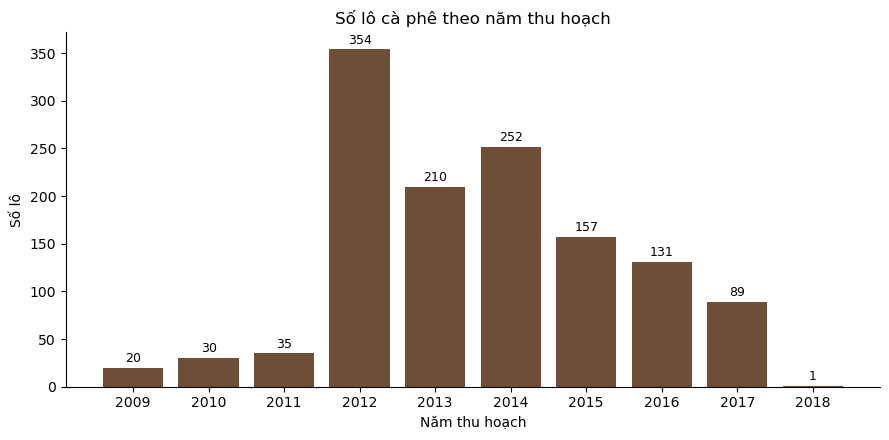

In [21]:
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(lots_per_year.index.astype(str), lots_per_year.values, color="#6F4E37")

ax.bar_label(bars, padding=2, fontsize=9)          # ghi số lô lên đầu mỗi cột
ax.set_title("Số lô cà phê theo năm thu hoạch")
ax.set_xlabel("Năm thu hoạch")
ax.set_ylabel("Số lô")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

<div style="background-color:#EEF3FB;border:1px solid #283E75;border-left:6px solid #283E75;border-radius:6px;padding:10px 18px;margin:10px 0;font-size:15.5px;line-height:1.65">

<b style="color:#283E75;letter-spacing:1px">NHẬN XÉT: GIAI ĐOẠN</b>

- Thu hoạch **2009–2018**; **60 lô (4,5%)** thiếu năm.
- Tập trung ở **2012–2016**: 1.104/1.279 lô (86,3%); nhiều nhất năm **2012** với 354 lô.
- 2009–2011 chỉ có 20 / 30 / 35 lô; **2018 chỉ 1 lô**.
- `Expiration`: 09/04/2011 → 19/01/2019. Chứng nhận có hạn 1 năm ⇒ lô được chấm khoảng 04/2010–01/2018, khớp thời điểm scrape (a).
- ⇒ **Q4** phải gộp/loại các năm ít lô; dữ liệu dừng ở 2018 nên không suy ra xu hướng hiện tại.

</div>

#### <span style="color:#3B5BA9">(d) Độ phủ theo quốc gia</span>

In [22]:
# Độ phủ theo quốc gia
lots_per_country = df["Country.of.Origin"].value_counts()          # giảm dần sẵn

small = lots_per_country[lots_per_country < 10]
top3_share = lots_per_country.head(3).sum() / len(df)

print(f"Số quốc gia                 : {lots_per_country.size}")
print(f"Quốc gia có < 10 lô         : {small.size} nước, chiếm {small.sum()} lô ({small.sum() / len(df):.1%})")
print(f"Top 3 quốc gia chiếm        : {top3_share:.1%} tổng số lô")

lots_per_country.to_frame("Số lô").assign(**{"Tỷ lệ (%)": lambda t: (t["Số lô"] / len(df) * 100).round(2)})

Số quốc gia                 : 34
Quốc gia có < 10 lô         : 14 nước, chiếm 45 lô (3.4%)
Top 3 quốc gia chiếm        : 44.8% tổng số lô


,Số lô,Tỷ lệ (%)
Country.of.Origin,,
Mexico,236,17.63
Colombia,183,13.67
Guatemala,181,13.52
Brazil,132,9.86
United States,87,6.50
Taiwan,75,5.60
Honduras,53,3.96
Costa Rica,51,3.81
Ethiopia,44,3.29


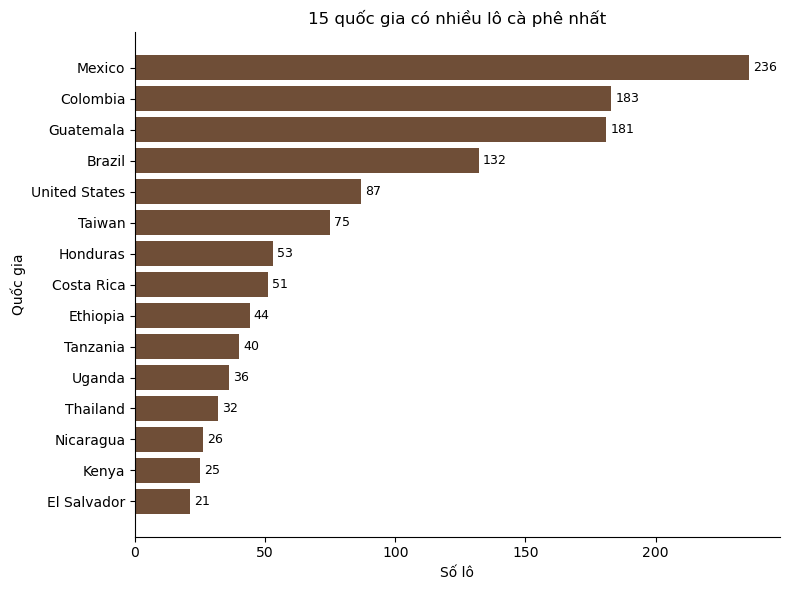

In [23]:
top15 = lots_per_country.head(15).sort_values()      # sắp tăng để cột dài nhất nằm trên cùng

fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.barh(top15.index, top15.values, color="#6F4E37")
ax.bar_label(bars, padding=3, fontsize=9)
ax.set_title("15 quốc gia có nhiều lô cà phê nhất")
ax.set_xlabel("Số lô")
ax.set_ylabel("Quốc gia")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

#### <span style="color:#3B5BA9">(e) By_Country / By_Continent có phải nguồn độc lập?</span>

<div style="font-size:15.5px;line-height:1.65">

**Giả thuyết:** đây chỉ là bảng tổng hợp từ file chính (`Rec_Cnt` = số lô, `AVG_*` = trung bình) → tự `groupby` rồi so sánh.

</div>

In [24]:
for name, table in [("df_country", df_country), ("df_continent", df_continent)]:
    print(f"=== {name}: {table.shape} ===")
    print(list(table.columns))
    display(table.head())

=== df_country: (34, 15) ===
['Country.of.Origin', 'AVG_Aroma', 'AVG_Flavor', 'AVG_Aftertaste', 'AVG_Acidity', 'AVG_Body', 'AVG_Balance', 'AVG_Uniformity', 'AVG_Clean.Cup', 'AVG_Sweetness', 'AVG_Moisture', 'AVG_Quakers', 'AVG_Category.One.Defects', 'AVG_Category.Two.Defects', 'Rec_Cnt']


,Country.of.Origin,AVG_Aroma,AVG_Flavor,AVG_Aftertaste,AVG_Acidity,AVG_Body,AVG_Balance,AVG_Uniformity,AVG_Clean.Cup,AVG_Sweetness,AVG_Moisture,AVG_Quakers,AVG_Category.One.Defects,AVG_Category.Two.Defects,Rec_Cnt
0,Brazil,7.553106,7.573561,7.440530,7.511439,7.544545,7.531515,9.884924,9.853485,9.949394,0.082348,0.446970,0.128788,3.598485,132
1,Burundi,7.415000,7.460000,7.250000,7.415000,7.290000,7.415000,10.000000,10.000000,10.000000,0.060000,0.000000,0.000000,2.500000,2
2,China,7.641250,7.625625,7.484375,7.578125,7.573750,7.548125,9.958125,9.958125,9.916250,0.094375,0.500000,0.000000,4.000000,16
3,Colombia,7.653060,7.597104,7.524699,7.560000,7.609508,7.708415,9.934426,9.945355,9.952678,0.062022,0.207650,0.377049,1.939891,183
4,Costa Rica,7.671373,7.537255,7.534510,7.573922,7.537451,7.637255,9.856275,9.869216,9.908431,0.083333,0.117647,0.352941,2.823529,51


=== df_continent: (5, 15) ===
['Country.of.Origin', 'AVG_Aroma', 'AVG_Flavor', 'AVG_Aftertaste', 'AVG_Acidity', 'AVG_Body', 'AVG_Balance', 'AVG_Uniformity', 'AVG_Clean.Cup', 'AVG_Sweetness', 'AVG_Moisture', 'AVG_Quakers', 'AVG_Category.One.Defects', 'AVG_Category.Two.Defects', 'Rec_Cnt']


,Country.of.Origin,AVG_Aroma,AVG_Flavor,AVG_Aftertaste,AVG_Acidity,AVG_Body,AVG_Balance,AVG_Uniformity,AVG_Clean.Cup,AVG_Sweetness,AVG_Moisture,AVG_Quakers,AVG_Category.One.Defects,AVG_Category.Two.Defects,Rec_Cnt
0,Africa,7.759444,7.709444,7.623889,7.739074,7.680741,7.689938,9.954568,9.979321,9.813148,0.100926,0.166667,0.179012,3.734568,162
1,Asia,7.539121,7.499286,7.409231,7.478407,7.509066,7.473187,9.908187,9.970604,9.761813,0.079066,0.115385,0.752747,1.538462,182
2,North America,7.504346,7.445714,7.300767,7.496677,7.450977,7.432496,9.752632,9.734226,9.852992,0.096857,0.129323,0.566917,4.518797,665
3,Oceania,8.330000,8.420000,7.830000,8.330000,8.000000,8.250000,9.330000,9.330000,10.000000,0.120000,0.000000,0.000000,1.000000,1
4,South America,7.613415,7.589878,7.491585,7.545915,7.574756,7.629177,9.902866,9.894268,9.937470,0.070030,0.298780,0.301829,2.646341,328


In [25]:
# Groupby rồi so sánh
# 1. Dò tên cột trong df_country
key_col   = df_country.select_dtypes(exclude="number").columns[0]   # cột tên quốc gia
count_col = [c for c in df_country.columns if "cnt" in c.lower()][0] # cột Rec_Cnt
avg_cols  = [c for c in df_country.columns if c.upper().startswith("AVG")]

def match_raw_col(avg_col):
    """'AVG_Clean_Cup' -> 'Clean.Cup' (cột tương ứng trong df), không thấy thì trả None."""
    base = avg_col[4:].lower().replace("_", "").replace(".", "")
    for c in df.columns:
        if c.lower().replace(".", "").replace("_", "") == base:
            return c
    return None

avg_map = {a: match_raw_col(a) for a in avg_cols}
print("Cột khoá:", key_col, "| Cột đếm:", count_col)
print("Ánh xạ AVG -> cột gốc:", avg_map)

# 2. Tự tổng hợp từ file chính
raw_cols = [c for c in avg_map.values() if c is not None]
mine = (df.groupby("Country.of.Origin")
          .agg(n_lots=("REC_ID", "size"), **{f"mine_{c}": (c, "mean") for c in raw_cols})
          .reset_index())

# 3. Ghép với df_country để so sánh
compare = df_country.merge(mine, left_on=key_col, right_on="Country.of.Origin",
                           how="outer", indicator=True)
print(compare["_merge"].value_counts())
compare[[key_col, count_col, "n_lots"] + avg_cols[:2] + [f"mine_{c}" for c in raw_cols[:2]]].head(10)

Cột khoá: Country.of.Origin | Cột đếm: Rec_Cnt
Ánh xạ AVG -> cột gốc: {'AVG_Aroma': 'Aroma', 'AVG_Flavor': 'Flavor', 'AVG_Aftertaste': 'Aftertaste', 'AVG_Acidity': 'Acidity', 'AVG_Body': 'Body', 'AVG_Balance': 'Balance', 'AVG_Uniformity': 'Uniformity', 'AVG_Clean.Cup': 'Clean.Cup', 'AVG_Sweetness': 'Sweetness', 'AVG_Moisture': 'Moisture', 'AVG_Quakers': 'Quakers', 'AVG_Category.One.Defects': 'Category.One.Defects', 'AVG_Category.Two.Defects': 'Category.Two.Defects'}
_merge
both          34
left_only      0
right_only     0
Name: count, dtype: int64


,Country.of.Origin,Rec_Cnt,n_lots,AVG_Aroma,AVG_Flavor,mine_Aroma,mine_Flavor
0,Brazil,132,132,7.553106,7.573561,7.553106,7.573561
1,Burundi,2,2,7.415000,7.460000,7.415000,7.460000
2,China,16,16,7.641250,7.625625,7.641250,7.625625
3,Colombia,183,183,7.653060,7.597104,7.653060,7.597104
4,Costa Rica,51,51,7.671373,7.537255,7.671373,7.537255
5,Cote dIvoire,1,1,7.420000,7.250000,7.420000,7.250000
6,Ecuador,3,3,7.583333,7.640000,7.583333,7.640000
7,El Salvador,21,21,7.674762,7.654286,7.674762,7.654286
8,Ethiopia,44,44,7.896364,8.009091,7.896364,8.009091
9,Guatemala,181,181,7.544862,7.489006,7.544862,7.489006


In [26]:
# TEST
both = compare[compare["_merge"] == "both"]

# a) mọi quốc gia đều khớp tên
assert (compare["_merge"] == "both").all(), \
    f"Có quốc gia không khớp tên:\n{compare.loc[compare['_merge'] != 'both', [key_col, 'Country.of.Origin', '_merge']]}"

# b) số lô khớp Rec_Cnt
assert (both[count_col] == both["n_lots"]).all(), \
    f"Số lô lệch ở:\n{both.loc[both[count_col] != both['n_lots'], [key_col, count_col, 'n_lots']]}"

# c) trung bình khớp (làm tròn 2 chữ số vì file tổng hợp có thể đã làm tròn)
for avg_col, raw_col in avg_map.items():
    if raw_col is None:
        continue
    ok = np.allclose(both[avg_col], both[f"mine_{raw_col}"].round(2), atol=0.01)
    assert ok, f"{avg_col} không khớp với trung bình của {raw_col}"

print(f"df_country được tổng hợp từ df: khớp {len(both)} quốc gia, {len(avg_map)} cột AVG")

df_country được tổng hợp từ df: khớp 34 quốc gia, 13 cột AVG


<div style="background-color:#EEF3FB;border:1px solid #283E75;border-left:6px solid #283E75;border-radius:6px;padding:10px 18px;margin:10px 0;font-size:15.5px;line-height:1.65">

<b style="color:#283E75;letter-spacing:1px">KẾT LUẬN (e)</b>

- `Rec_Cnt` và 13 cột `AVG_*` **khớp hoàn toàn** với `groupby` trên file chính cho cả 34 quốc gia và 5 châu lục (sai lệch ≈ 10⁻¹⁵, chỉ là sai số dấu phẩy động).
- ⇒ **Không phải nguồn độc lập**, không thêm thông tin mới. *(Cột khoá của `By_Continent` tên là `Country.of.Origin` dù chứa châu lục.)*
- Vì vậy D1 dùng **FAOSTAT** (Q5) để bổ sung quy mô sản xuất từng quốc gia; `By_Country` chỉ để đối chiếu / dự phòng.

</div>

#### <span style="color:#3B5BA9">(f) Hạn chế và thiên lệch đã biết</span>

<div style="font-size:15.5px;line-height:1.65">

| Hạn chế | Bằng chứng | Ảnh hưởng |
|:---|:---|:---|
| Thiên lệch chọn mẫu | Chỉ gồm lô được **gửi tới CQI** | Kết luận chỉ áp dụng cho các lô này |
| Mất cân bằng loài | Arabica 1.311 (97,91%) · Robusta 28 (2,09%) | Có thể chỉ phân tích Arabica |
| Độ phủ quốc gia lệch | 14/34 nước < 10 lô (6 nước chỉ 1 lô); top 3 chiếm 44,8% | So sánh nước nhỏ không ổn định |
| Dữ liệu cũ | 2009–2018; 60 lô thiếu năm; 2018 chỉ 1 lô | Không suy ra xu hướng hiện tại |
| Thiếu biến | Không có tổng điểm, độ cao, giá | Tự tạo `total_9` |
| Lỗi nhập liệu | Giá trị 0, outlier (xem 3.2) | Cần làm sạch |

</div>

<div style="background-color:#EEF3FB;border:1px solid #283E75;border-left:6px solid #283E75;border-radius:6px;padding:10px 18px;margin:10px 0;font-size:15.5px;line-height:1.65">

<b style="color:#283E75;letter-spacing:1px">TÓM TẮT COLLECTION METHOD</b>

- **Cách thu thập:** scrape từ CQI (01/2018) → qua tay Volpatto (2019), Boyar (2023) → RealDealAdamP công bố (03/2024).
- **Quần thể:** 1.339 lô, 34 quốc gia, 5 châu lục; 97,91% Arabica; châu Mỹ > 74% (Bắc Mỹ 49,66%, Nam Mỹ 24,50%).
- **Giai đoạn:** thu hoạch 2009–2018, tập trung 2012–2016; chấm khoảng 04/2010–01/2018.
- **Hạn chế:** thiên lệch chọn mẫu, lệch loài, lệch quốc gia, dữ liệu cũ, thiếu biến.

➜ **Phạm vi kết luận:** các lô **Arabica được CQI chấm trong giai đoạn 2010–2018**.

</div>

### <span style="color:#283E75">▍3.1.5 · Motivation</span>

<div style="font-size:15.5px;line-height:1.65">

| Lý do | Tóm tắt |
|:---|:---|
| **1. Ý nghĩa thực tế** | Điểm CQI ≥ 80 = *specialty*, bán giá cao hơn → trả lời *"điều gì làm nên lô cà phê chất lượng cao?"* cho **nông hộ** (giống, sơ chế, độ ẩm, lỗi hạt), **nhà nhập khẩu / rang xay** (nguồn hàng), **barista / người tiêu dùng** (ý nghĩa điểm số) |
| **2. Hợp yêu cầu đồ án** | Dữ liệu thật · 13 biến số + nhiều biến phân loại + 2 biến thời gian · đủ chất liệu cho D1 (FAOSTAT), D2 (xu hướng năm), D3 (`total_9`), D4 (kiểm tra theo nhóm) · có bài toán ML tự nhiên · kích thước 1.339 × 22 vừa phải |
| **3. Chưa bị khai thác nhiều** | Khác Iris/Titanic, ít được dùng làm ví dụ mẫu. *TODO (Hiếu, theo `docs/related_work.md`): số notebook công khai trên Kaggle và điểm khác biệt của nhóm* |
| **4. Liên hệ câu hỏi** | **Q2 (ML):** … · **Q4:** … · **Q5:** … |

</div>

### <span style="color:#283E75">▍3.1.6 · Các file dữ liệu và cách nhóm sử dụng</span>

In [27]:
# Tóm tắt 3 file
row_meaning = {
    MAIN_FILE.name:      "Một lô cà phê được CQI chấm điểm",
    COUNTRY_FILE.name:   "Một quốc gia (trung bình các chỉ số + số lô)",
    CONTINENT_FILE.name: "Một châu lục (trung bình các chỉ số + số lô)",
}
tables = {MAIN_FILE.name: df, COUNTRY_FILE.name: df_country, CONTINENT_FILE.name: df_continent}

files_summary = pd.DataFrame({
    "File":          list(tables.keys()),
    "Số dòng":       [t.shape[0] for t in tables.values()],
    "Số cột":        [t.shape[1] for t in tables.values()],
    "Một dòng là gì": [row_meaning[name] for name in tables],
})
files_summary

,File,Số dòng,Số cột,Một dòng là gì
0,Coffee_Qlty.csv,1339,22,Một lô cà phê được CQI chấm điểm
1,Coffee_Qlty_By_Country.csv,34,15,Một quốc gia (trung bình các chỉ số + số lô)
2,Coffee_Qlty_By_Continent.csv,5,15,Một châu lục (trung bình các chỉ số + số lô)


<div style="font-size:15.5px;line-height:1.65">

| File | Kích thước | Một dòng là | Dùng cho |
|:---|:---|:---|:---|
| `Coffee_Qlty.csv` | 1.339 × 22 | Một lô cà phê | **File chính**: exploration, Q1–Q6, ML |
| `Coffee_Qlty_By_Country.csv` | 34 × 15 | Một quốc gia (`AVG_*`, `Rec_Cnt`) | Đối chiếu, dự phòng cho D1 |
| `Coffee_Qlty_By_Continent.csv` | 5 × 15 | Một châu lục (khoá tên `Country.of.Origin`) | Đối chiếu |

</div>

<div style="background-color:#283E75;color:#ffffff;padding:14px 24px;border-radius:8px;margin-top:24px">

<span style="font-size:17px;font-weight:700;letter-spacing:3px;color:#E3EBFA">PHẦN 3.2</span>

## <span style="color:#ffffff">Data exploration</span>

<span style="font-size:15px;color:#DCE6F7">Cấu trúc, phân phối, dữ liệu thiếu và quan hệ giữa các biến</span>

</div>

### <span style="color:#283E75">▍3.2.1 · Overview</span>

#### <span style="color:#3B5BA9">a. Kích thước, mẫu dữ liệu và khoá <code>REC_ID</code></span>

In [28]:
# Kiểm tra kích thước, kiểu dữ liệu tổng quát và tính duy nhất của khoá REC_ID
overview_stats = pd.DataFrame([
    {"Chỉ tiêu": "Số dòng (bản ghi lô cà phê)", "Giá trị": f"{df.shape[0]:,}"},
    {"Chỉ tiêu": "Số cột gốc", "Giá trị": f"{df.shape[1]}"},
    {"Chỉ tiêu": "Số giá trị REC_ID duy nhất", "Giá trị": f"{df['REC_ID'].nunique():,}"},
    {"Chỉ tiêu": "REC_ID là khoá duy nhất (is_unique)", "Giá trị": str(bool(df["REC_ID"].is_unique))},
    {"Chỉ tiêu": "Số dòng rỗng hoàn toàn (all-NA)", "Giá trị": f"{int(df.isna().all(axis=1).sum())}"},
])
display(overview_stats)
print("5 dòng đầu tiên của dữ liệu:")
display(df.head(5))

,Chỉ tiêu,Giá trị
0,Số dòng (bản ghi lô cà phê),"1,339"
1,Số cột gốc,22
2,Số giá trị REC_ID duy nhất,"1,339"
3,REC_ID là khoá duy nhất (is_unique),True
4,Số dòng rỗng hoàn toàn (all-NA),0


5 dòng đầu tiên của dữ liệu (df.head(5)):


,REC_ID,Species,Continent.of.Origin,Country.of.Origin,Harvest.Year,Expiration,Variety,Color,Processing.Method,Aroma,Flavor,Aftertaste,Acidity,Body,Balance,Uniformity,Clean.Cup,Sweetness,Moisture,Quakers,Category.One.Defects,Category.Two.Defects
0,0,Arabica,Africa,Ethiopia,2014.0,04/03/16,NaN,Green,Washed / Wet,8.67,8.83,8.67,8.75,8.50,8.42,10.0,10.0,10.0,0.12,0,0,0
1,1,Arabica,Africa,Ethiopia,2014.0,04/03/16,Other,Green,Washed / Wet,8.75,8.67,8.50,8.58,8.42,8.42,10.0,10.0,10.0,0.12,0,0,1
2,2,Arabica,North America,Guatemala,NaN,05/31/11,Bourbon,NaN,NaN,8.42,8.50,8.42,8.42,8.33,8.42,10.0,10.0,10.0,0.00,0,0,0
3,3,Arabica,Africa,Ethiopia,2014.0,03/25/16,NaN,Green,Natural / Dry,8.17,8.58,8.42,8.42,8.50,8.25,10.0,10.0,10.0,0.11,0,0,2
4,4,Arabica,Africa,Ethiopia,2014.0,04/03/16,Other,Green,Washed / Wet,8.25,8.50,8.25,8.50,8.42,8.33,10.0,10.0,10.0,0.12,0,0,2


#### <span style="color:#3B5BA9">b. Từ điển dữ liệu &amp; kiểu dữ liệu</span>

<div style="font-size:15.5px;line-height:1.65">

Mô tả 22 cột: vai trò, ý nghĩa, miền giá trị, kiểu đọc từ CSV → kiểu mục tiêu, `n_unique`, `n_missing` và quyết định xử lý.

</div>

In [29]:
COLUMN_SPECS = [
    ("REC_ID", "Định danh", "Mã bản ghi lô cà phê trong CQI", "Số nguyên [0..1338]", "int64", "Giữ làm khoá truy vết ở EDA; bỏ khi phân tích/ML"),
    ("Species", "Xuất xứ", "Loài cà phê", "Arabica / Robusta", "category", "Giữ; kiểm tra mất cân bằng loài (97,91% Arabica)"),
    ("Continent.of.Origin", "Xuất xứ", "Châu lục xuất xứ của lô cà phê", "Tên châu lục (5 nhóm)", "category", "Giữ; chuẩn hoá nhãn"),
    ("Country.of.Origin", "Xuất xứ", "Quốc gia xuất xứ của lô cà phê", "Tên quốc gia (34 nước)", "category", "Giữ; chuẩn hoá nhãn và nối FAOSTAT ở Q5"),
    ("Harvest.Year", "Thông tin lô", "Năm thu hoạch lô cà phê", "Năm (YYYY, 2009–2018)", "Int64", "Ép sang Int64 vì float64 do có 60 ô NaN"),
    ("Expiration", "Thông tin lô", "Ngày hết hạn chứng nhận CQI (1 năm sau chấm)", "Ngày (MM/DD/YY)", "datetime64[ns]", "Ép sang datetime để đối chiếu mốc thời gian"),
    ("Variety", "Thông tin lô", "Giống cây cà phê", "Tên giống (29 nhãn)", "category", "Giữ; chuẩn hoá và tạo bản gộp nhóm hiếm (<20 lô)"),
    ("Color", "Thông tin lô", "Màu sắc hạt cà phê nhân xanh trước khi rang", "Green, Bluish-Green, Blue-Green, None", "category", "Giữ; lưu ý nhãn chuỗi 'None' (52 lô) khác với NaN"),
    ("Processing.Method", "Thông tin lô", "Phương pháp sơ chế sau thu hoạch", "Washed / Wet, Natural / Dry, ...", "category", "Giữ; biến trọng tâm cho Q1"),
    ("Aroma", "Cảm quan", "Điểm hương thơm (khô và sau khi pha nước)", "Điểm SCA (thang 0–10)", "float64", "Giữ; thành phần tính total_9"),
    ("Flavor", "Cảm quan", "Điểm hương vị chủ đạo khi nếm", "Điểm SCA (thang 0–10)", "float64", "Giữ; thành phần tính total_9"),
    ("Aftertaste", "Cảm quan", "Điểm hậu vị lưu lại sau khi nuốt/nhổ", "Điểm SCA (thang 0–10)", "float64", "Giữ; thành phần tính total_9"),
    ("Acidity", "Cảm quan", "Điểm độ chua thanh/tươi sáng", "Điểm SCA (thang 0–10)", "float64", "Giữ; thành phần tính total_9"),
    ("Body", "Cảm quan", "Điểm độ sánh đậm/cảm giác miệng", "Điểm SCA (thang 0–10)", "float64", "Giữ; thành phần tính total_9"),
    ("Balance", "Cảm quan", "Điểm độ cân bằng giữa Flavor, Aftertaste, Acidity, Body", "Điểm SCA (thang 0–10)", "float64", "Giữ; thành phần tính total_9"),
    ("Uniformity", "Cảm quan", "Độ đồng nhất hương vị giữa 5 tách mẫu (2 điểm/tách)", "Điểm SCA (0–10, bước 2)", "float64", "Giữ; lưu ý hiệu ứng trần điểm (86,1% đạt 10)"),
    ("Clean.Cup", "Cảm quan", "Độ sạch vị, không có mùi vị lạ trên 5 tách mẫu", "Điểm SCA (0–10, bước 2)", "float64", "Giữ; lưu ý hiệu ứng trần điểm (91,1% đạt 10)"),
    ("Sweetness", "Cảm quan", "Độ ngọt tự nhiên cảm nhận trên 5 tách mẫu", "Điểm SCA (0–10, bước 2)", "float64", "Giữ; lưu ý hiệu ứng trần điểm (91,0% đạt 10)"),
    ("Moisture", "Vật lý / lỗi hạt", "Độ ẩm của hạt cà phê nhân xanh (tỷ lệ phần thập phân)", "Tỷ lệ [0,00–0,28] (10% = 0,10)", "float64", "Giữ; kiểm tra 264 lô có Moisture = 0,00"),
    ("Quakers", "Vật lý / lỗi hạt", "Số hạt chưa chín (quakers) phát hiện sau khi rang mẫu", "Số hạt nguyên >= 0", "int64", "Giữ; biến phân tích Q3 và đặc trưng ML Q2"),
    ("Category.One.Defects", "Vật lý / lỗi hạt", "Số lỗi sơ cấp (nặng: hạt đen, chua toàn phần...) trên 350g nhân", "Số lỗi nguyên >= 0", "int64", "Giữ; biến phân tích Q3 và đặc trưng ML Q2"),
    ("Category.Two.Defects", "Vật lý / lỗi hạt", "Số lỗi thứ cấp (nhẹ: hạt vỡ, vỏ trấu, sâu đục...) trên 350g nhân", "Số lỗi nguyên >= 0", "int64", "Giữ; biến phân tích Q3 và đặc trưng ML Q2"),
]

data_dictionary = pd.DataFrame(
    COLUMN_SPECS,
    columns=["column", "group", "meaning", "unit_or_range", "target_dtype", "decision"],
)
data_dictionary["current_dtype"] = [str(df[c].dtype) for c in data_dictionary["column"]]
data_dictionary["n_unique"] = [int(df[c].nunique(dropna=True)) for c in data_dictionary["column"]]
data_dictionary["n_missing"] = [int(df[c].isna().sum()) for c in data_dictionary["column"]]
data_dictionary["pct_missing"] = [round(df[c].isna().mean() * 100, 2) for c in data_dictionary["column"]]

cols_order = [
    "column", "group", "meaning", "unit_or_range",
    "current_dtype", "target_dtype", "n_unique", "n_missing", "pct_missing", "decision"
]
data_dictionary = data_dictionary[cols_order]
display(data_dictionary)

,column,group,meaning,unit_or_range,current_dtype,target_dtype,n_unique,n_missing,pct_missing,decision
0,REC_ID,Định danh,Mã bản ghi lô cà phê trong CQI,Số nguyên [0..1338],int64,int64,1339,0,0.00,Giữ làm khoá truy vết ở EDA; bỏ khi phân tích/ML
1,Species,Xuất xứ,Loài cà phê,Arabica / Robusta,object,category,2,0,0.00,"Giữ; kiểm tra mất cân bằng loài (97,91% Arabica)"
2,Continent.of.Origin,Xuất xứ,Châu lục xuất xứ của lô cà phê,Tên châu lục (5 nhóm),object,category,5,1,0.07,Giữ; chuẩn hoá nhãn
3,Country.of.Origin,Xuất xứ,Quốc gia xuất xứ của lô cà phê,Tên quốc gia (34 nước),object,category,34,1,0.07,Giữ; chuẩn hoá nhãn và nối FAOSTAT ở Q5
4,Harvest.Year,Thông tin lô,Năm thu hoạch lô cà phê,"Năm (YYYY, 2009–2018)",float64,Int64,10,60,4.48,Ép sang Int64 vì float64 do có 60 ô NaN
5,Expiration,Thông tin lô,Ngày hết hạn chứng nhận CQI (1 năm sau chấm),Ngày (MM/DD/YY),object,datetime64[ns],565,0,0.00,Ép sang datetime để đối chiếu mốc thời gian
6,Variety,Thông tin lô,Giống cây cà phê,Tên giống (29 nhãn),object,category,29,226,16.88,Giữ; chuẩn hoá và tạo bản gộp nhóm hiếm (<20 lô)
7,Color,Thông tin lô,Màu sắc hạt cà phê nhân xanh trước khi rang,"Green, Bluish-Green, Blue-Green, None",object,category,4,218,16.28,Giữ; lưu ý nhãn chuỗi 'None' (52 lô) khác với NaN
8,Processing.Method,Thông tin lô,Phương pháp sơ chế sau thu hoạch,"Washed / Wet, Natural / Dry, ...",object,category,5,170,12.70,Giữ; biến trọng tâm cho Q1
9,Aroma,Cảm quan,Điểm hương thơm (khô và sau khi pha nước),Điểm SCA (thang 0–10),float64,float64,33,0,0.00,Giữ; thành phần tính total_9


#### <span style="color:#3B5BA9">c. Dòng trùng, cột hằng số và ép kiểu (<code>errors='coerce'</code>)</span>

In [30]:
# 1. Kiểm tra cột hằng số (chỉ có 1 giá trị)
constant_cols = [c for c in df.columns if df[c].nunique(dropna=True) <= 1]

# 2. Kiểm tra dòng trùng toàn bộ và dòng trùng trên 21 cột ngoài REC_ID
n_full_dup = int(df.duplicated().sum())
non_id_cols = [c for c in df.columns if c != "REC_ID"]
n_attr_dup_pairs = int(df.duplicated(subset=non_id_cols, keep="first").sum())
attr_dup_rows = df[df.duplicated(subset=non_id_cols, keep=False)].sort_values("REC_ID")

print(f"Số cột chỉ có <= 1 giá trị duy nhất : {len(constant_cols)} ({constant_cols})")
print(f"Số dòng trùng tuyệt đối cả 22 cột   : {n_full_dup}")
print(f"Số cặp dòng trùng toàn bộ 21 cột ngoài REC_ID: {n_attr_dup_pairs} cặp ({len(attr_dup_rows)} dòng)")
print("\nChi tiết 2 bản ghi trùng toàn bộ thuộc tính ngoài REC_ID:")
display(attr_dup_rows)

# 3. Kiểm toán ép kiểu (coercion audit) cho cột thời gian và các cột số
coercion_rows = []
# Kiểm tra Harvest.Year
hy_coerced = pd.to_numeric(df["Harvest.Year"], errors="coerce")
coercion_rows.append({
    "column": "Harvest.Year",
    "original_dtype": str(df["Harvest.Year"].dtype),
    "target_conversion": "pd.to_numeric(..., errors='coerce') -> Int64",
    "na_before": int(df["Harvest.Year"].isna().sum()),
    "na_after": int(hy_coerced.isna().sum()),
    "new_na_from_dirty_values": int(hy_coerced.isna().sum() - df["Harvest.Year"].isna().sum()),
})

# Kiểm tra Expiration
exp_coerced = pd.to_datetime(df["Expiration"], format="%m/%d/%y", errors="coerce")
coercion_rows.append({
    "column": "Expiration",
    "original_dtype": str(df["Expiration"].dtype),
    "target_conversion": "pd.to_datetime(..., format='%m/%d/%y', errors='coerce')",
    "na_before": int(df["Expiration"].isna().sum()),
    "na_after": int(exp_coerced.isna().sum()),
    "new_na_from_dirty_values": int(exp_coerced.isna().sum() - df["Expiration"].isna().sum()),
})

# Kiểm tra 13 cột số (9 cảm quan + 4 vật lý)
for col in SCORE_COLS + ["Moisture", "Quakers", "Category.One.Defects", "Category.Two.Defects"]:
    num_coerced = pd.to_numeric(df[col], errors="coerce")
    coercion_rows.append({
        "column": col,
        "original_dtype": str(df[col].dtype),
        "target_conversion": "pd.to_numeric(..., errors='coerce')",
        "na_before": int(df[col].isna().sum()),
        "na_after": int(num_coerced.isna().sum()),
        "new_na_from_dirty_values": int(num_coerced.isna().sum() - df[col].isna().sum()),
    })

coercion_audit = pd.DataFrame(coercion_rows).set_index("column")
print("\nBảng kiểm toán ép kiểu (số NaN mới sinh = số chuỗi bẩn không đọc được):")
display(coercion_audit)

Số cột chỉ có <= 1 giá trị duy nhất : 0 ([])
Số dòng trùng tuyệt đối cả 22 cột   : 0
Số cặp dòng trùng toàn bộ 21 cột ngoài REC_ID: 1 cặp (2 dòng)

Chi tiết 2 bản ghi trùng toàn bộ thuộc tính ngoài REC_ID:


,REC_ID,Species,Continent.of.Origin,Country.of.Origin,Harvest.Year,Expiration,Variety,Color,Processing.Method,Aroma,Flavor,Aftertaste,Acidity,Body,Balance,Uniformity,Clean.Cup,Sweetness,Moisture,Quakers,Category.One.Defects,Category.Two.Defects
721,721,Arabica,Asia,Taiwan,2013.0,12/26/14,Typica,Green,Washed / Wet,7.5,7.5,7.5,7.5,7.5,7.5,10.0,10.0,10.0,0.11,0,0,0
742,742,Arabica,Asia,Taiwan,2013.0,12/26/14,Typica,Green,Washed / Wet,7.5,7.5,7.5,7.5,7.5,7.5,10.0,10.0,10.0,0.11,0,0,0



Bảng kiểm toán ép kiểu (số NaN mới sinh = số chuỗi bẩn không đọc được):


,original_dtype,target_conversion,na_before,na_after,new_na_from_dirty_values
column,,,,,
Harvest.Year,float64,"pd.to_numeric(..., errors='coerce') -> Int64",60,60,0
Expiration,object,"pd.to_datetime(..., format='%m/%d/%y', errors=...",0,0,0
Aroma,float64,"pd.to_numeric(..., errors='coerce')",0,0,0
Flavor,float64,"pd.to_numeric(..., errors='coerce')",0,0,0
Aftertaste,float64,"pd.to_numeric(..., errors='coerce')",0,0,0
Acidity,float64,"pd.to_numeric(..., errors='coerce')",0,0,0
Body,float64,"pd.to_numeric(..., errors='coerce')",0,0,0
Balance,float64,"pd.to_numeric(..., errors='coerce')",0,0,0
Uniformity,float64,"pd.to_numeric(..., errors='coerce')",0,0,0


In [31]:
# TEST — Kiểm tra tính toàn vẹn của mục 3.2.1 Overview
assert df.shape == (1339, 22), "df gốc phải giữ nguyên 1.339 dòng × 22 cột"
assert len(data_dictionary) == 22, "Từ điển dữ liệu phải mô tả đủ 22 cột"
assert set(data_dictionary["column"]) == set(df.columns), "Các cột trong từ điển phải khớp với df.columns"
assert len(constant_cols) == 0, "Không có cột hằng số nào trong dữ liệu"
assert n_full_dup == 0, "Không có dòng trùng tuyệt đối cả 22 cột"
assert set(attr_dup_rows["REC_ID"]) == {721, 742}, "Hai bản ghi trùng thuộc tính ngoài REC_ID phải là 721 và 742"
assert (coercion_audit["new_na_from_dirty_values"] == 0).all(), "Không phát sinh NaN mới khi ép kiểu"
print("Overview checks passed")

Overview checks passed


<div style="background-color:#EEF3FB;border:1px solid #283E75;border-left:6px solid #283E75;border-radius:6px;padding:10px 18px;margin:10px 0;font-size:15.5px;line-height:1.65">

<b style="color:#283E75;letter-spacing:1px">NHẬN XÉT: OVERVIEW</b>

- **1.339 dòng × 22 cột**, không có dòng rỗng. `REC_ID` (0–1338) duy nhất, chỉ dùng để truy vết, không làm biến mô hình.
- **Ép kiểu:** 13 cột số đã đúng kiểu, không có chuỗi bẩn (0 NaN mới). Cần đổi:
  - `Harvest.Year`: `float64` → `Int64` (60 NaN; 1.279 giá trị là năm 2009–2018).
  - `Expiration`: chuỗi `MM/DD/YY` → datetime (1.339/1.339 dòng hợp lệ).
- **Cặp trùng `REC_ID` 721 &amp; 742:** giống hệt ở cả 21 cột còn lại (Arabica · Taiwan · 2013 · Typica · Washed / Wet · `total_9` = 74,24).
- **Quyết định:** giữ ở bước EDA; kiểm tra độ nhạy và **bỏ bản lặp trước khi chia train/test (Q2)** để tránh rò rỉ dữ liệu.

</div>

### <span style="color:#283E75">▍3.2.2 · Numerical columns</span>

#### <span style="color:#3B5BA9">a. Bản ghi lỗi điểm cảm quan và thống kê trước / sau</span>

<div style="font-size:15.5px;line-height:1.65">

Thang chấm là 0–10 nhưng lô thực tế thường đạt 5–10 → rà các giá trị **0** ở 9 cột cảm quan và 4 cột vật lý.

</div>

In [32]:
PHYS_COLS = ["Moisture", "Quakers", "Category.One.Defects", "Category.Two.Defects"]
df_num_raw = add_total_score(df)
NUM_ANALYZE_COLS = [*SCORE_COLS, "total_9", *PHYS_COLS]

# Kiểm tra các dòng có bất kỳ cột cảm quan nào bằng 0
zero_sensory_mask = df_num_raw[SCORE_COLS].eq(0).any(axis=1)
print(f"Số lô có ít nhất 1 thuộc tính cảm quan bằng 0: {int(zero_sensory_mask.sum())} lô")
display(
    df_num_raw.loc[
        zero_sensory_mask,
        ["REC_ID", "Species", "Country.of.Origin", "Harvest.Year", *SCORE_COLS, "total_9", "Moisture", "Category.Two.Defects"]
    ]
)

Số lô có ít nhất 1 thuộc tính cảm quan bằng 0: 2 lô


,REC_ID,Species,Country.of.Origin,Harvest.Year,Aroma,Flavor,Aftertaste,Acidity,Body,Balance,Uniformity,Clean.Cup,Sweetness,total_9,Moisture,Category.Two.Defects
1306,1306,Arabica,Mexico,2012.0,7.08,6.83,6.25,7.42,7.25,6.75,10.0,0.0,10.0,61.58,0.11,20
1310,1310,Arabica,Honduras,2017.0,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.0,0.0,0.00,0.12,2


<div style="font-size:15.5px;line-height:1.65">

Có **2 lô** có điểm cảm quan bằng 0, nhưng bản chất khác nhau:

| | `REC_ID = 1310` | `REC_ID = 1306` |
|:---|:---|:---|
| Xuất xứ | Honduras, 2017 | Mexico, 2012 |
| Điểm 0 | **Cả 9 thuộc tính** (`total_9` = 0) | Chỉ `Clean.Cup` |
| Phần còn lại | Vật lý bình thường (Moisture 0,12; 2 lỗi Cat. 2) | 8 thuộc tính hợp lệ, `total_9` = 61,58; 20 lỗi Cat. 2 |
| Kết luận | **Lỗi dữ liệu**: số 0 giữ chỗ cho lô chưa có kết quả cupping → **tách ra** | **Giá trị thật**: lô kém chất lượng → **giữ lại** |

Bảng dưới: thống kê mô tả trên **1.338 lô hợp lệ** và so sánh `total_9` trước / sau khi bỏ `REC_ID = 1310`.

</div>

In [33]:
df_num_valid = df_num_raw.loc[df_num_raw["REC_ID"].ne(1310)].copy()

# So sánh tác động của duy nhất 1 dòng REC_ID=1310 lên thống kê total_9
impact_1310 = pd.DataFrame([
    {
        "Mẫu": "Toàn bộ 1.339 lô (gồm REC_ID=1310)",
        "n": len(df_num_raw),
        "mean_total_9": df_num_raw["total_9"].mean(),
        "median_total_9": df_num_raw["total_9"].median(),
        "std_total_9": df_num_raw["total_9"].std(),
        "min_total_9": df_num_raw["total_9"].min(),
        "skew_total_9": df_num_raw["total_9"].skew(),
        "kurt_total_9": df_num_raw["total_9"].kurt(),
    },
    {
        "Mẫu": "1.338 lô hợp lệ (đã bỏ REC_ID=1310)",
        "n": len(df_num_valid),
        "mean_total_9": df_num_valid["total_9"].mean(),
        "median_total_9": df_num_valid["total_9"].median(),
        "std_total_9": df_num_valid["total_9"].std(),
        "min_total_9": df_num_valid["total_9"].min(),
        "skew_total_9": df_num_valid["total_9"].skew(),
        "kurt_total_9": df_num_valid["total_9"].kurt(),
    },
])
print("Tác động của bản ghi placeholder REC_ID=1310 lên biến tổng điểm total_9:")
display(impact_1310.round(3))

# Bảng thống kê chi tiết cho 14 biến số trên 1.338 lô hợp lệ
num_summary = df_num_valid[NUM_ANALYZE_COLS].describe().T
num_summary["median"] = df_num_valid[NUM_ANALYZE_COLS].median()
num_summary["IQR"] = num_summary["75%"] - num_summary["25%"]
num_summary["mean_minus_median"] = num_summary["mean"] - num_summary["median"]
num_summary["skew"] = df_num_valid[NUM_ANALYZE_COLS].skew()
num_summary["kurt"] = df_num_valid[NUM_ANALYZE_COLS].kurt()
num_summary["n_zeros"] = df_num_valid[NUM_ANALYZE_COLS].eq(0).sum()
num_summary["pct_zeros"] = (df_num_valid[NUM_ANALYZE_COLS].eq(0).mean() * 100).round(2)
num_summary["pct_equal_10"] = (df_num_valid[NUM_ANALYZE_COLS].eq(10.0).mean() * 100).round(2)

summary_cols = [
    "count", "mean", "median", "mean_minus_median", "std", "IQR",
    "min", "25%", "75%", "max", "skew", "kurt", "n_zeros", "pct_zeros", "pct_equal_10"
]
print("\nBảng thống kê mô tả 14 biến số trên mẫu 1.338 lô hợp lệ:")
display(num_summary[summary_cols].round(3))

Tác động của bản ghi placeholder REC_ID=1310 lên biến tổng điểm total_9:


,Mẫu,n,mean_total_9,median_total_9,std_total_9,min_total_9,skew_total_9,kurt_total_9
0,Toàn bộ 1.339 lô (gồm REC_ID=1310),1339,74.586,75.0,3.139,0.00,-10.954,240.911
1,1.338 lô hợp lệ (đã bỏ REC_ID=1310),1338,74.642,75.0,2.387,53.17,-2.152,11.169



Bảng thống kê mô tả 14 biến số trên mẫu 1.338 lô hợp lệ:


,count,mean,median,mean_minus_median,std,IQR,min,25%,75%,max,skew,kurt,n_zeros,pct_zeros,pct_equal_10
Aroma,1338.0,7.572,7.58,-0.008,0.316,0.330,5.08,7.420,7.75,8.75,-0.430,3.791,0,0.00,0.00
Flavor,1338.0,7.526,7.58,-0.054,0.341,0.420,6.08,7.330,7.75,8.83,-0.308,1.618,0,0.00,0.00
Aftertaste,1338.0,7.407,7.42,-0.013,0.350,0.330,6.17,7.250,7.58,8.67,-0.363,1.273,0,0.00,0.00
Acidity,1338.0,7.541,7.58,-0.039,0.319,0.420,5.25,7.330,7.75,8.75,-0.218,2.684,0,0.00,0.00
Body,1338.0,7.523,7.50,0.023,0.308,0.340,5.08,7.330,7.67,8.58,-0.962,7.719,0,0.00,0.00
Balance,1338.0,7.524,7.50,0.024,0.354,0.420,5.25,7.330,7.75,8.75,-0.253,2.174,0,0.00,0.00
Uniformity,1338.0,9.842,10.00,-0.158,0.485,0.000,6.00,10.000,10.00,10.00,-4.219,21.371,0,0.00,86.10
Clean.Cup,1338.0,9.842,10.00,-0.158,0.715,0.000,0.00,10.000,10.00,10.00,-7.158,66.163,1,0.07,91.11
Sweetness,1338.0,9.864,10.00,-0.136,0.554,0.000,1.33,10.000,10.00,10.00,-6.219,57.169,0,0.00,91.03
total_9,1338.0,74.642,75.00,-0.358,2.387,2.098,53.17,73.822,75.92,81.84,-2.152,11.169,0,0.00,0.00


#### <span style="color:#3B5BA9">b. Outlier theo IQR (1,5 · 3,0) và Z-score (|z| &gt; 3)</span>

In [34]:
outlier_rows = []
for col in NUM_ANALYZE_COLS:
    s = df_num_valid[col].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    low_15, high_15 = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    low_30, high_30 = q1 - 3.0 * iqr, q3 + 3.0 * iqr
    z_scores = (s - s.mean()) / s.std()

    n_low_15 = int((s < low_15).sum())
    n_high_15 = int((s > high_15).sum())
    n_out_15 = n_low_15 + n_high_15
    n_out_30 = int(((s < low_30) | (s > high_30)).sum())
    n_z_gt3 = int((z_scores.abs() > 3).sum())

    outlier_rows.append({
        "column": col,
        "Q1": round(q1, 3),
        "Q3": round(q3, 3),
        "IQR": round(iqr, 3),
        "fence_low_1.5": round(low_15, 3),
        "fence_high_1.5": round(high_15, 3),
        "n_low_1.5IQR": n_low_15,
        "n_high_1.5IQR": n_high_15,
        "n_total_1.5IQR": n_out_15,
        "pct_1.5IQR": round(n_out_15 / len(s) * 100, 2),
        "n_total_3.0IQR": n_out_30,
        "n_abs_z_gt3": n_z_gt3,
    })

outlier_table = pd.DataFrame(outlier_rows).set_index("column")
display(outlier_table)

,Q1,Q3,IQR,fence_low_1.5,fence_high_1.5,n_low_1.5IQR,n_high_1.5IQR,n_total_1.5IQR,pct_1.5IQR,n_total_3.0IQR,n_abs_z_gt3
column,,,,,,,,,,,
Aroma,7.420,7.75,0.330,6.925,8.245,39,32,71,5.31,5,10
Flavor,7.330,7.75,0.420,6.700,8.380,26,17,43,3.21,0,23
Aftertaste,7.250,7.58,0.330,6.755,8.075,56,30,86,6.43,12,22
Acidity,7.330,7.75,0.420,6.700,8.380,9,15,24,1.79,1,13
Body,7.330,7.67,0.340,6.820,8.180,13,20,33,2.47,3,11
Balance,7.330,7.75,0.420,6.700,8.380,16,23,39,2.91,1,9
Uniformity,10.000,10.00,0.000,10.000,10.000,186,0,186,13.90,186,37
Clean.Cup,10.000,10.00,0.000,10.000,10.000,119,0,119,8.89,119,29
Sweetness,10.000,10.00,0.000,10.000,10.000,120,0,120,8.97,120,46


#### <span style="color:#3B5BA9">c. Phân phối 9 thuộc tính cảm quan và <code>total_9</code></span>

<div style="font-size:15.5px;line-height:1.65">

| Nhóm | Cột | Đặc điểm |
|:---|:---|:---|
| **Chấm liên tục** | Aroma, Flavor, Aftertaste, Acidity, Body, Balance | Thường nằm trong 6,0–8,8 điểm |
| **Chấm theo cốc** | Uniformity, Clean.Cup, Sweetness | 5 cốc × 2 điểm → **trần điểm**: 86,10–91,11% lô đạt 10 ⇒ Q1 = Q3 = 10, IQR = 0 |

</div>

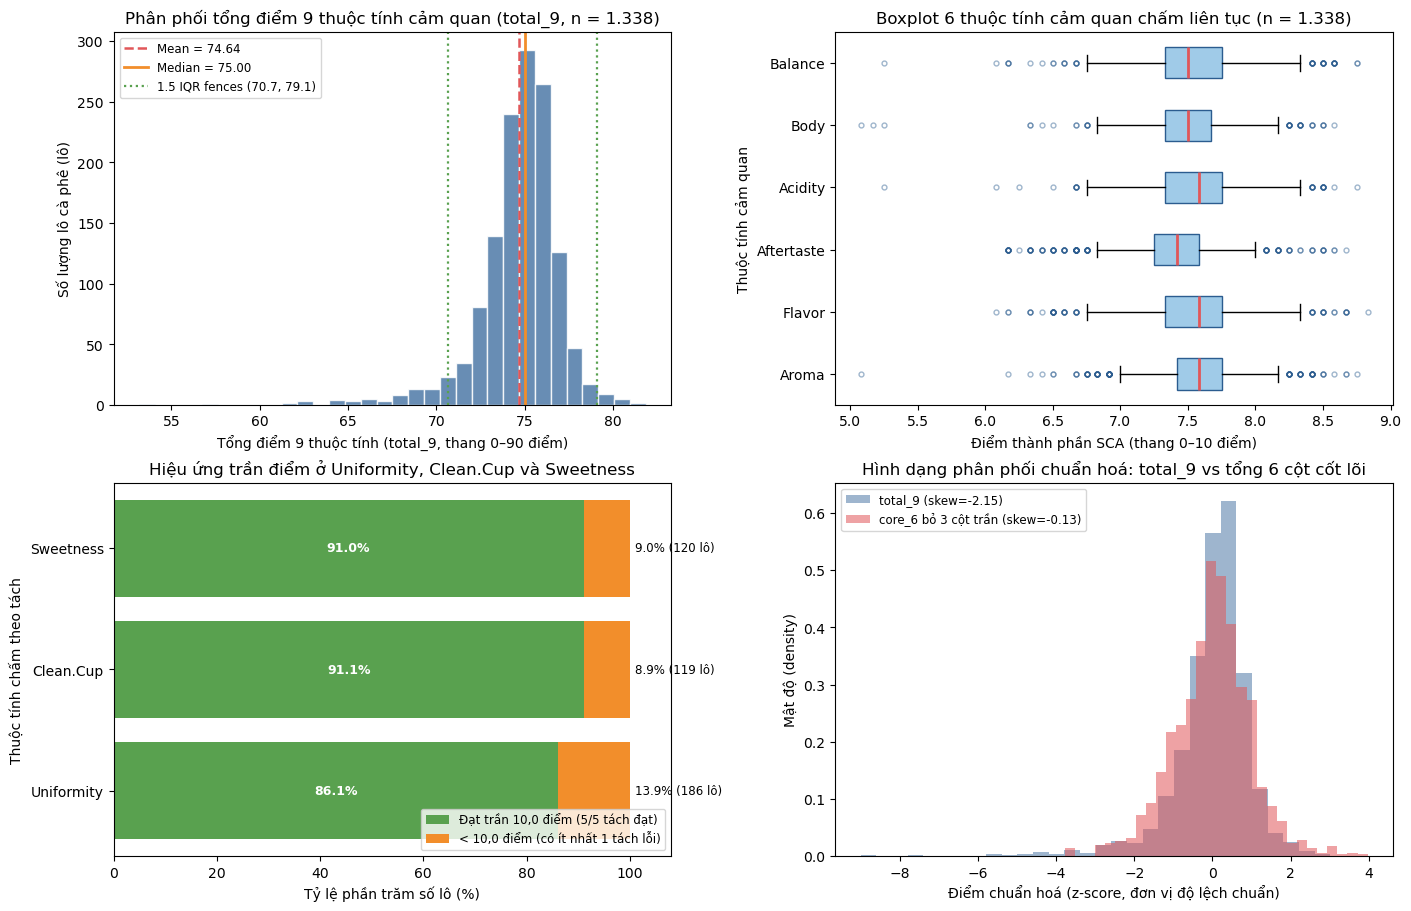

In [35]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9), layout="constrained")

# 1. Histogram của total_9 kèm mean, median và ngưỡng 1.5 IQR
ax = axes[0, 0]
s_tot = df_num_valid["total_9"]
q1_t, q3_t = s_tot.quantile([0.25, 0.75])
iqr_t = q3_t - q1_t
ax.hist(s_tot, bins=32, color="#4E79A7", edgecolor="white", alpha=0.85)
ax.axvline(s_tot.mean(), color="#E15759", linestyle="--", linewidth=1.8, label=f"Mean = {s_tot.mean():.2f}")
ax.axvline(s_tot.median(), color="#F28E2B", linestyle="-", linewidth=2.0, label=f"Median = {s_tot.median():.2f}")
ax.axvline(q1_t - 1.5 * iqr_t, color="#59A14F", linestyle=":", linewidth=1.6, label=f"1.5 IQR fences ({q1_t - 1.5*iqr_t:.1f}, {q3_t + 1.5*iqr_t:.1f})")
ax.axvline(q3_t + 1.5 * iqr_t, color="#59A14F", linestyle=":", linewidth=1.6)
ax.set_title("Phân phối tổng điểm 9 thuộc tính cảm quan (total_9, n = 1.338)")
ax.set_xlabel("Tổng điểm 9 thuộc tính (total_9, thang 0–90 điểm)")
ax.set_ylabel("Số lượng lô cà phê (lô)")
ax.legend(fontsize=8.5)

# 2. Boxplot của 6 thuộc tính cảm quan liên tục
ax = axes[0, 1]
core6_cols = ["Aroma", "Flavor", "Aftertaste", "Acidity", "Body", "Balance"]
bp = ax.boxplot(
    [df_num_valid[c].dropna() for c in core6_cols],
    labels=core6_cols,
    vert=False,
    patch_artist=True,
    boxprops=dict(facecolor="#A0CBE8", edgecolor="#2B5C8F"),
    medianprops=dict(color="#E15759", linewidth=2),
    flierprops=dict(marker="o", markersize=3.5, alpha=0.45, markeredgecolor="#2B5C8F"),
)
ax.set_title("Boxplot 6 thuộc tính cảm quan chấm liên tục (n = 1.338)")
ax.set_xlabel("Điểm thành phần SCA (thang 0–10 điểm)")
ax.set_ylabel("Thuộc tính cảm quan")

# 3. Tỷ lệ đạt trần điểm 10.0 vs < 10.0 của 3 thuộc tính chấm theo tách
ax = axes[1, 0]
ceiling_cols = ["Uniformity", "Clean.Cup", "Sweetness"]
pct_10 = [(df_num_valid[c] == 10.0).mean() * 100 for c in ceiling_cols]
pct_lt10 = [(df_num_valid[c] < 10.0).mean() * 100 for c in ceiling_cols]
y_pos = np.arange(len(ceiling_cols))
b1 = ax.barh(y_pos, pct_10, color="#59A14F", label="Đạt trần 10,0 điểm (5/5 tách đạt)")
b2 = ax.barh(y_pos, pct_lt10, left=pct_10, color="#F28E2B", label="< 10,0 điểm (có ít nhất 1 tách lỗi)")
ax.set_yticks(y_pos, ceiling_cols)
ax.set_xlim(0, 108)
ax.set_xlabel("Tỷ lệ phần trăm số lô (%)")
ax.set_ylabel("Thuộc tính chấm theo tách")
ax.set_title("Hiệu ứng trần điểm ở Uniformity, Clean.Cup và Sweetness")
for idx, (p10, plt10) in enumerate(zip(pct_10, pct_lt10)):
    ax.text(p10 / 2, idx, f"{p10:.1f}%", va="center", ha="center", color="white", fontweight="bold", fontsize=9)
    ax.text(p10 + plt10 + 1, idx, f"{plt10:.1f}% ({int(round(plt10*len(df_num_valid)/100))} lô)", va="center", fontsize=8.5)
ax.legend(loc="lower right", fontsize=8.5)

# 4. So sánh phân phối tổng 6 cột cốt lõi (core_6) vs tổng 9 cột (total_9) chuẩn hoá z-score
ax = axes[1, 1]
core_6_sum = df_num_valid[core6_cols].sum(axis=1)
z_tot9 = (s_tot - s_tot.mean()) / s_tot.std()
z_core6 = (core_6_sum - core_6_sum.mean()) / core_6_sum.std()
ax.hist(z_tot9, bins=30, alpha=0.55, color="#4E79A7", label=f"total_9 (skew={s_tot.skew():.2f})", density=True)
ax.hist(z_core6, bins=30, alpha=0.55, color="#E15759", label=f"core_6 bỏ 3 cột trần (skew={core_6_sum.skew():.2f})", density=True)
ax.set_title("Hình dạng phân phối chuẩn hoá: total_9 vs tổng 6 cột cốt lõi")
ax.set_xlabel("Điểm chuẩn hoá (z-score, đơn vị độ lệch chuẩn)")
ax.set_ylabel("Mật độ (density)")
ax.legend(fontsize=8.5)

plt.show()

#### <span style="color:#3B5BA9">d. Bốn biến vật lý &amp; lỗi hạt</span>


In [36]:
# So sánh thống kê Moisture khi giữ nguyên 264 số 0 vs khi xem Moisture == 0 là khuyết (chỉ xét Moisture > 0)
moisture_all = df_num_valid["Moisture"]
moisture_pos = df_num_valid.loc[df_num_valid["Moisture"] > 0, "Moisture"]

moisture_compare = pd.DataFrame([
    {
        "Kịch bản": "Giữ toàn bộ (gồm 264 lô Moisture = 0.00)",
        "n_lots": len(moisture_all),
        "mean": moisture_all.mean(),
        "median": moisture_all.median(),
        "std": moisture_all.std(),
        "Q1": moisture_all.quantile(0.25),
        "Q3": moisture_all.quantile(0.75),
        "IQR": moisture_all.quantile(0.75) - moisture_all.quantile(0.25),
        "fence_low_1.5IQR": moisture_all.quantile(0.25) - 1.5 * (moisture_all.quantile(0.75) - moisture_all.quantile(0.25)),
        "fence_high_1.5IQR": moisture_all.quantile(0.75) + 1.5 * (moisture_all.quantile(0.75) - moisture_all.quantile(0.25)),
    },
    {
        "Kịch bản": "Chỉ xét các lô có đo độ ẩm dương (Moisture > 0)",
        "n_lots": len(moisture_pos),
        "mean": moisture_pos.mean(),
        "median": moisture_pos.median(),
        "std": moisture_pos.std(),
        "Q1": moisture_pos.quantile(0.25),
        "Q3": moisture_pos.quantile(0.75),
        "IQR": moisture_pos.quantile(0.75) - moisture_pos.quantile(0.25),
        "fence_low_1.5IQR": moisture_pos.quantile(0.25) - 1.5 * (moisture_pos.quantile(0.75) - moisture_pos.quantile(0.25)),
        "fence_high_1.5IQR": moisture_pos.quantile(0.75) + 1.5 * (moisture_pos.quantile(0.75) - moisture_pos.quantile(0.25)),
    },
])
print("Đối chiếu phân phối Moisture trước và sau khi tách 264 lô có Moisture = 0.00:")
display(moisture_compare.round(4))

# Kiểm tra các lô có lỗi hạt cực đoan nhất để xác minh là dữ liệu thật hay lỗi nhập liệu
print("\nTop 5 lô có Category.One.Defects cao nhất (kèm điểm total_9 để đối chiếu):")
display(
    df_num_valid.nlargest(5, "Category.One.Defects")[
        ["REC_ID", "Species", "Country.of.Origin", "Harvest.Year", "Category.One.Defects", "Category.Two.Defects", "Quakers", "total_9"]
    ]
)
print("\nTop 5 lô có Category.Two.Defects cao nhất:")
display(
    df_num_valid.nlargest(5, "Category.Two.Defects")[
        ["REC_ID", "Species", "Country.of.Origin", "Harvest.Year", "Category.One.Defects", "Category.Two.Defects", "Quakers", "total_9"]
    ]
)

Đối chiếu phân phối Moisture trước và sau khi tách 264 lô có Moisture = 0.00:


,Kịch bản,n_lots,mean,median,std,Q1,Q3,IQR,fence_low_1.5IQR,fence_high_1.5IQR
0,Giữ toàn bộ (gồm 264 lô Moisture = 0.00),1338,0.0884,0.11,0.0483,0.09,0.12,0.03,0.045,0.165
1,Chỉ xét các lô có đo độ ẩm dương (Moisture > 0),1074,0.1101,0.11,0.0227,0.10,0.12,0.02,0.070,0.150



Top 5 lô có Category.One.Defects cao nhất (kèm điểm total_9 để đối chiếu):


,REC_ID,Species,Country.of.Origin,Harvest.Year,Category.One.Defects,Category.Two.Defects,Quakers,total_9
1338,1338,Robusta,Vietnam,2013.0,63,9,0,65.83
536,536,Arabica,Taiwan,2016.0,31,0,0,75.17
1229,1229,Arabica,Mexico,2012.0,31,47,0,71.08
1279,1279,Arabica,Mexico,2012.0,23,29,0,68.43
1337,1337,Robusta,India,2013.0,20,1,0,68.16



Top 5 lô có Category.Two.Defects cao nhất:


,REC_ID,Species,Country.of.Origin,Harvest.Year,Category.One.Defects,Category.Two.Defects,Quakers,total_9
1302,1302,Arabica,Brazil,2017.0,0,55,1,63.99
1229,1229,Arabica,Mexico,2012.0,31,47,0,71.08
1195,1195,Arabica,Mexico,2012.0,0,45,0,72.16
250,250,Arabica,Ethiopia,2013.0,4,40,0,76.17
1203,1203,Arabica,Mexico,2012.0,7,38,0,72.17


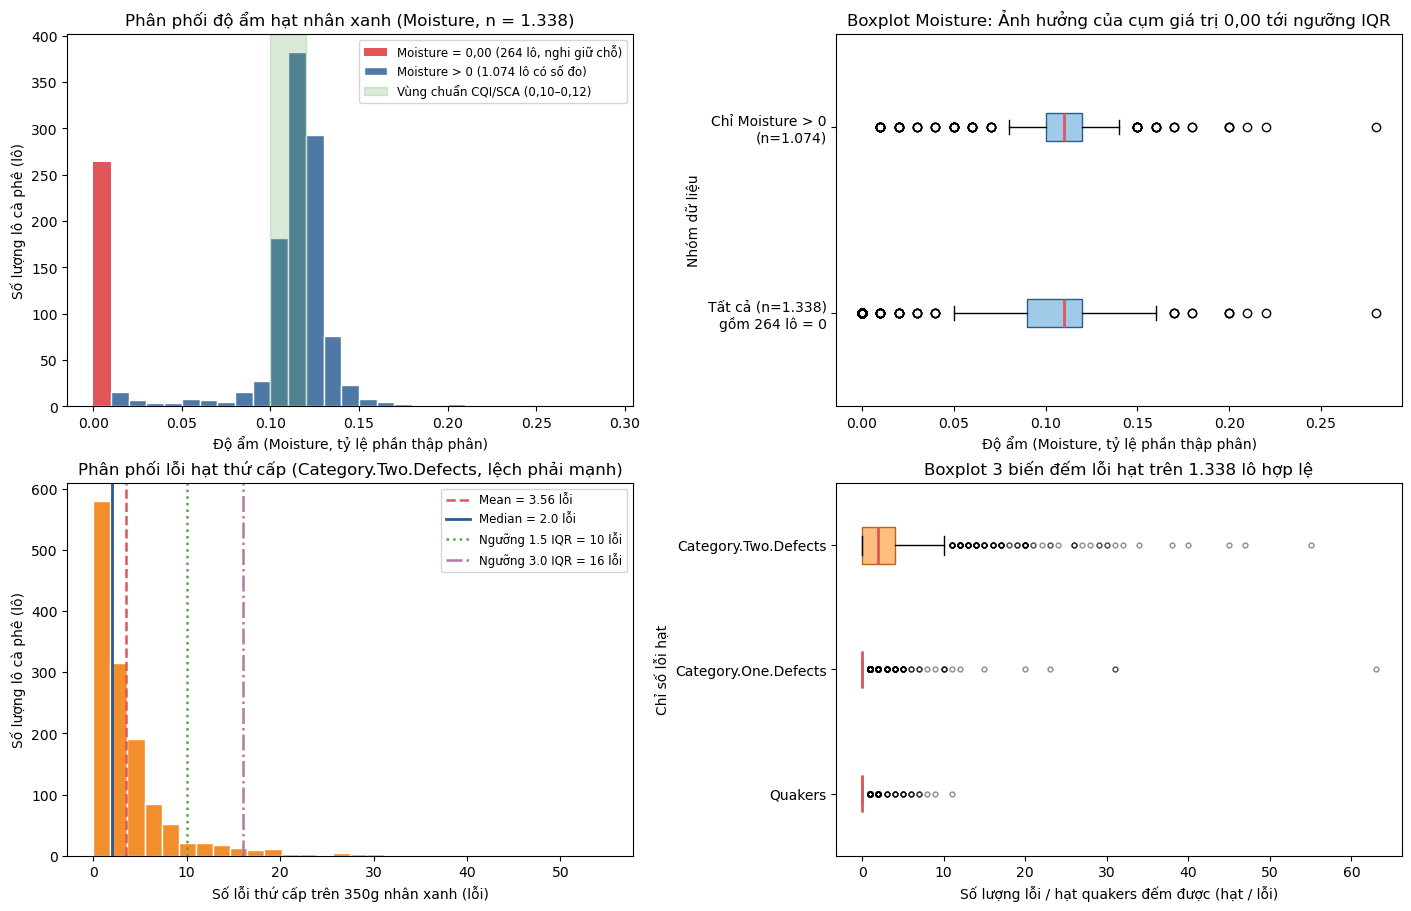

In [37]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9), layout="constrained")

# 1. Phân phối Moisture (đánh dấu cụm 0.00 và vùng chuẩn bảo quản 0.10 - 0.12)
ax = axes[0, 0]
bins_m = np.linspace(0, 0.29, 30)
ax.hist(df_num_valid.loc[df_num_valid["Moisture"] == 0, "Moisture"], bins=bins_m, color="#E15759", label="Moisture = 0,00 (264 lô, nghi giữ chỗ)")
ax.hist(df_num_valid.loc[df_num_valid["Moisture"] > 0, "Moisture"], bins=bins_m, color="#4E79A7", edgecolor="white", label="Moisture > 0 (1.074 lô có số đo)")
ax.axvspan(0.10, 0.12, color="#59A14F", alpha=0.22, label="Vùng chuẩn CQI/SCA (0,10–0,12)")
ax.set_title("Phân phối độ ẩm hạt nhân xanh (Moisture, n = 1.338)")
ax.set_xlabel("Độ ẩm (Moisture, tỷ lệ phần thập phân)")
ax.set_ylabel("Số lượng lô cà phê (lô)")
ax.legend(fontsize=8.5)

# 2. Boxplot Moisture: Toàn bộ vs Moisture > 0
ax = axes[0, 1]
ax.boxplot(
    [moisture_all, moisture_pos],
    labels=["Tất cả (n=1.338)\ngồm 264 lô = 0", "Chỉ Moisture > 0\n(n=1.074)"],
    vert=False,
    patch_artist=True,
    boxprops=dict(facecolor="#A0CBE8", edgecolor="#2B5C8F"),
    medianprops=dict(color="#E15759", linewidth=2),
)
ax.set_title("Boxplot Moisture: Ảnh hưởng của cụm giá trị 0,00 tới ngưỡng IQR")
ax.set_xlabel("Độ ẩm (Moisture, tỷ lệ phần thập phân)")
ax.set_ylabel("Nhóm dữ liệu")

# 3. Phân phối Category.Two.Defects
ax = axes[1, 0]
s_cat2 = df_num_valid["Category.Two.Defects"]
q1_c2, q3_c2 = s_cat2.quantile([0.25, 0.75])
iqr_c2 = q3_c2 - q1_c2
ax.hist(s_cat2, bins=30, color="#F28E2B", edgecolor="white")
ax.axvline(s_cat2.mean(), color="#E15759", linestyle="--", linewidth=1.8, label=f"Mean = {s_cat2.mean():.2f} lỗi")
ax.axvline(s_cat2.median(), color="#2B5C8F", linestyle="-", linewidth=2.0, label=f"Median = {s_cat2.median():.1f} lỗi")
ax.axvline(q3_c2 + 1.5 * iqr_c2, color="#59A14F", linestyle=":", linewidth=1.8, label=f"Ngưỡng 1.5 IQR = {q3_c2 + 1.5*iqr_c2:.0f} lỗi")
ax.axvline(q3_c2 + 3.0 * iqr_c2, color="#B07AA1", linestyle="-.", linewidth=1.8, label=f"Ngưỡng 3.0 IQR = {q3_c2 + 3.0*iqr_c2:.0f} lỗi")
ax.set_title("Phân phối lỗi hạt thứ cấp (Category.Two.Defects, lệch phải mạnh)")
ax.set_xlabel("Số lỗi thứ cấp trên 350g nhân xanh (lỗi)")
ax.set_ylabel("Số lượng lô cà phê (lô)")
ax.legend(fontsize=8.5)

# 4. Boxplot so sánh 3 biến đếm lỗi hạt (Category.One.Defects, Category.Two.Defects, Quakers)
ax = axes[1, 1]
defect_cols = ["Quakers", "Category.One.Defects", "Category.Two.Defects"]
ax.boxplot(
    [df_num_valid[c] for c in defect_cols],
    labels=defect_cols,
    vert=False,
    patch_artist=True,
    boxprops=dict(facecolor="#FFBE7D", edgecolor="#B66325"),
    medianprops=dict(color="#E15759", linewidth=2),
    flierprops=dict(marker="o", markersize=3.5, alpha=0.45),
)
ax.set_title("Boxplot 3 biến đếm lỗi hạt trên 1.338 lô hợp lệ")
ax.set_xlabel("Số lượng lỗi / hạt quakers đếm được (hạt / lỗi)")
ax.set_ylabel("Chỉ số lỗi hạt")

plt.show()

In [38]:
# TEST — Kiểm tra tính chính xác của mục 3.2.2 Numerical columns
assert len(df_num_valid) == 1338, "Mẫu hợp lệ sau khi bỏ REC_ID=1310 phải có đúng 1.338 lô"
assert int((df["REC_ID"] == 1310).sum()) == 1, "REC_ID=1310 phải tồn tại trong df gốc"
assert (df.loc[df["REC_ID"] == 1310, SCORE_COLS] == 0).all(axis=None), "REC_ID=1310 có cả 9 điểm bằng 0"
assert int((df_num_valid["Moisture"] == 0).sum()) == 264, "Phải có đúng 264 lô có Moisture = 0.00"
assert outlier_table.loc["Category.Two.Defects", "n_total_1.5IQR"] == 94, "Category.Two.Defects có 94 outlier theo 1.5 IQR"
assert outlier_table.loc["Category.Two.Defects", "n_total_3.0IQR"] == 43, "Category.Two.Defects có 43 outlier theo 3.0 IQR"
print("Numerical columns checks passed")

Numerical columns checks passed


<div style="background-color:#EEF3FB;border:1px solid #283E75;border-left:6px solid #283E75;border-radius:6px;padding:10px 18px;margin:10px 0;font-size:15.5px;line-height:1.65">

<b style="color:#283E75;letter-spacing:1px">NHẬN XÉT: NUMERICAL COLUMNS</b>

- **`REC_ID = 1310`** kéo skew của `total_9` về −10,954 (kurtosis 240,911). Sau khi bỏ: mean **74,64** · median **75,00** · IQR 73,82–75,92 · min 53,17 · max 81,84 · skew −2,152.
- **6 thuộc tính liên tục:** gần đối xứng (|skew| &lt; 1), quanh 7,40–7,58 điểm, IQR 0,33–0,42 → phân biệt chất lượng tốt nhất.
- **3 thuộc tính theo cốc:** trần điểm 86,10% / 91,11% / 91,03% đạt 10 ⇒ 186 / 119 / 120 lô bị gắn "outlier" oan → cơ sở cho **Q6** (Tùng Hiếu).
- **Moisture:** 264 số 0 kéo mean xuống 0,088 (median 0,110). Chỉ xét **1.074 lô &gt; 0**: mean 0,1101 · IQR 0,10–0,12 · **79,89%** nằm trong dải chuẩn 10–12%.
- **Lỗi hạt:** lệch phải (skew 3,67–15,06). Các lô nhiều lỗi nhất (1338: 63 lỗi Cat. 1; 1302: 55 lỗi Cat. 2; 1229: 31 + 47 lỗi) đều có điểm thấp ⇒ **lỗi thật, không xoá**. Q3 sẽ so với ngưỡng 1,5 IQR (&gt; 10 lỗi Cat. 2, 94 lô) và 3,0 IQR (&gt; 16, 43 lô) → **D6**.

</div>

### <span style="color:#283E75">▍3.2.3 · Categorical columns</span>

<div style="font-size:15.5px;line-height:1.65">

**Mục tiêu:** kiểm kê 6 cột phân loại (`Species`, `Continent.of.Origin`, `Country.of.Origin`, `Variety`, `Color`, `Processing.Method`) trước khi chuẩn hoá và gộp nhóm hiếm. **Không xoá dòng nào.**

</div>

<span style="color:#5B6B8C;font-size:14px">Ô trống → giá trị thiếu · chuỗi <code>"None"</code> → một nhãn riêng cần xác minh.</span>

#### <span style="color:#3B5BA9">a. Số nhãn, độ thiếu và mức tập trung</span>

<span style="color:#5B6B8C;font-size:14px">Tỷ lệ tính trên <b>toàn bộ số dòng</b>; <code>n_unique_nonmissing</code> không tính giá trị thiếu.</span>

In [39]:
from IPython.display import HTML


def display_centered_table(table):
    """Center column headings and values in the displayed table."""
    html = table.to_html(notebook=True)
    html = html.replace("<th>", '<th style="text-align: center !important;">')
    html = html.replace("<td>", '<td style="text-align: center !important;">')
    display(HTML(html))


missing_columns = set(CAT_COLS) - set(df.columns)
if missing_columns:
    raise ValueError(f"Thiếu các cột bắt buộc: {sorted(missing_columns)}")
if df.empty:
    raise ValueError("Dữ liệu đầu vào không có dòng.")

n_rows = len(df)
summary_rows = []
for column in CAT_COLS:
    counts = df[column].value_counts(dropna=True)
    top_label = counts.index[0] if not counts.empty else pd.NA
    top_count = int(counts.iloc[0]) if not counts.empty else 0
    summary_rows.append({
        "column": column,
        "n_unique_nonmissing": df[column].nunique(dropna=True),
        "n_missing": int(df[column].isna().sum()),
        "missing_pct_all": df[column].isna().mean() * 100,
        "top_label": top_label,
        "top_n": top_count,
        "top_pct_all": top_count / n_rows * 100,
    })
cat_summary = pd.DataFrame(summary_rows).set_index("column")
display_centered_table(cat_summary.reset_index().round(2))

,column,n_unique_nonmissing,n_missing,missing_pct_all,top_label,top_n,top_pct_all
0,Species,2,0,0.00,Arabica,1311,97.91
1,Continent.of.Origin,5,1,0.07,North America,665,49.66
2,Country.of.Origin,34,1,0.07,Mexico,236,17.63
3,Variety,29,226,16.88,Caturra,256,19.12
4,Color,4,218,16.28,Green,870,64.97
5,Processing.Method,5,170,12.70,Washed / Wet,815,60.87


#### <span style="color:#3B5BA9">b. Top 5 nhãn của từng cột</span>

<span style="color:#5B6B8C;font-size:14px"><code>pct_all</code>: trên mọi dòng · <code>pct_known</code>: trên các dòng có nhãn. Tổng top 5 có thể &lt; 100% vì còn nhãn khác và giá trị thiếu.</span>

In [40]:
top5_tables = {}
for column in CAT_COLS:
    counts = df[column].value_counts(dropna=True)
    known_n = int(df[column].notna().sum())
    table = counts.head(5).rename_axis("label").reset_index(name="n_lots")
    table.insert(0, "rank", range(1, len(table) + 1))
    table["pct_all"] = table["n_lots"] / n_rows * 100
    table["pct_known"] = table["n_lots"] / known_n * 100 if known_n else float("nan")
    top5_tables[column] = table
    print(f"{column} — đã biết: {known_n:,}; thiếu: {n_rows - known_n:,}")
    display_centered_table(table.round(2).rename(columns={"n_lots": "Number of coffee lots"}))

Species — đã biết: 1,339; thiếu: 0


,rank,label,Number of coffee lots,pct_all,pct_known
0,1,Arabica,1311,97.91,97.91
1,2,Robusta,28,2.09,2.09


Continent.of.Origin — đã biết: 1,338; thiếu: 1


,rank,label,Number of coffee lots,pct_all,pct_known
0,1,North America,665,49.66,49.70
1,2,South America,328,24.50,24.51
2,3,Asia,182,13.59,13.60
3,4,Africa,162,12.10,12.11
4,5,Oceania,1,0.07,0.07


Country.of.Origin — đã biết: 1,338; thiếu: 1


,rank,label,Number of coffee lots,pct_all,pct_known
0,1,Mexico,236,17.63,17.64
1,2,Colombia,183,13.67,13.68
2,3,Guatemala,181,13.52,13.53
3,4,Brazil,132,9.86,9.87
4,5,United States,87,6.50,6.50


... (2 outputs left out)

Color — đã biết: 1,121; thiếu: 218


,rank,label,Number of coffee lots,pct_all,pct_known
0,1,Green,870,64.97,77.61
1,2,Bluish-Green,114,8.51,10.17
2,3,Blue-Green,85,6.35,7.58
3,4,None,52,3.88,4.64


Processing.Method — đã biết: 1,169; thiếu: 170


,rank,label,Number of coffee lots,pct_all,pct_known
0,1,Washed / Wet,815,60.87,69.72
1,2,Natural / Dry,258,19.27,22.07
2,3,Semi-washed / Semi-pulped,56,4.18,4.79
3,4,Other,26,1.94,2.22
4,5,Pulped natural / honey,14,1.05,1.20


#### <span style="color:#3B5BA9">c. Cơ cấu Species</span>

<span style="color:#5B6B8C;font-size:14px">Dùng toàn bộ dữ liệu để đo mức mất cân bằng; bước này <b>chưa loại Robusta</b>.</span>

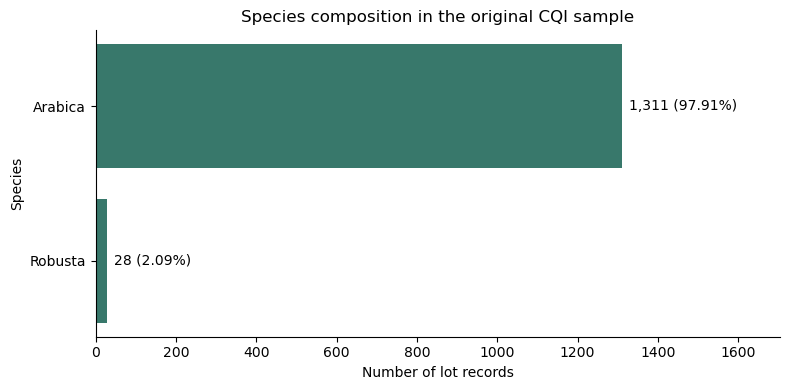

In [41]:
species_counts = df["Species"].fillna("Missing").value_counts()
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(species_counts.index, species_counts.values, color="#38786b")
ax.invert_yaxis()
ax.set_title("Species composition in the original CQI sample")
ax.set_xlabel("Number of lot records")
ax.set_ylabel("Species")
ax.set_xlim(0, species_counts.max() * 1.3)
ax.bar_label(bars, labels=[f"{n:,} ({n / n_rows:.2%})" for n in species_counts], padding=5)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

#### <span style="color:#3B5BA9">d. Độ tập trung và các nhóm &lt; 20 lô</span>

In [42]:
balance_rows = []
for column in CAT_COLS:
    counts = df[column].value_counts(dropna=True)
    known_n = int(counts.sum())
    balance_rows.append({
        "column": column,
        "top_pct_known": counts.iloc[0] / known_n * 100 if known_n else float("nan"),
        "n_categories_lt20": int(counts.lt(20).sum()),
        "n_lots_in_categories_lt20": int(counts[counts.lt(20)].sum()),
    })
display_centered_table(pd.DataFrame(balance_rows).round(2))

arabica_mask = df["Species"].eq("Arabica")
scope_options = pd.DataFrame([
    {"scope": "All species (current)", "n_lots": n_rows, "retained_pct": 100.0},
    {"scope": "Arabica only (proposal)", "n_lots": int(arabica_mask.sum()),
     "retained_pct": arabica_mask.mean() * 100},
])
display_centered_table(scope_options.round(2).rename(columns={"n_lots": "Number of coffee lots"}))
print("Chưa áp dụng bộ lọc Species. Cần nhóm thống nhất phạm vi trước khi lọc.")

,column,top_pct_known,n_categories_lt20,n_lots_in_categories_lt20
0,Species,97.91,0,0
1,Continent.of.Origin,49.70,1,1
2,Country.of.Origin,17.64,18,96
3,Variety,23.00,20,104
4,Color,77.61,0,0
5,Processing.Method,69.72,1,14


,scope,Number of coffee lots,retained_pct
0,All species (current),1339,100.00
1,Arabica only (proposal),1311,97.91


Chưa áp dụng bộ lọc Species. Cần nhóm thống nhất phạm vi trước khi lọc.


#### <span style="color:#3B5BA9">e. Kiểm tra tính nhất quán</span>

<span style="color:#5B6B8C;font-size:14px">Xác nhận số đếm, mẫu số và nhãn <code>None</code> không bị mất do cách đọc file. Không loại dòng.</span>

In [43]:
assert len(df) == n_rows
for column in CAT_COLS:
    assert df[column].value_counts().sum() + df[column].isna().sum() == n_rows
    table = top5_tables[column]
    assert len(table) <= 5
    assert table["n_lots"].sum() <= df[column].notna().sum()
    assert table["pct_all"].between(0, 100).all()
print(f"Đã kiểm tra {len(CAT_COLS)} cột; số dòng trước/sau: {n_rows:,}/{len(df):,}.")
print("Color literal 'None':", int(df["Color"].eq("None").sum()))

Đã kiểm tra 6 cột; số dòng trước/sau: 1,339/1,339.
Color literal 'None': 52


#### <span style="color:#3B5BA9">f. Chuẩn hoá nhãn</span>

<div style="font-size:15.5px;line-height:1.65">

- Tạo bản sao `df_labels`; chỉ sửa 6 cột phân loại bằng `src/labels.py`: **cắt khoảng trắng → `casefold` → ánh xạ tên quốc gia**. Giữ `df` để đối chiếu.
- **Không** tự gộp giống / màu / sơ chế chỉ vì viết gần giống; **không** gộp Hawaii hay vùng lãnh thổ vào quốc gia; ánh xạ này chưa phải tên FAOSTAT.
- `"None"` → `"none"` (vẫn khác ô thiếu) · `Other` → `other` (khác nhóm gộp tự động).

</div>

In [44]:
# Mọi lần chạy lại đều bắt đầu từ dữ liệu gốc.
df_labels = normalize_labels(df)
REVIEW_COLS = ["Country.of.Origin", "Variety", "Processing.Method"]
normalization_summary = pd.DataFrame([
    {
        "column": column,
        "unique_before": df[column].nunique(dropna=True),
        "unique_after": df_labels[column].nunique(dropna=True),
        "missing_before": int(df[column].isna().sum()),
        "missing_after": int(df_labels[column].isna().sum()),
        "changed_rows": int(
            df[column].astype("string").fillna("<MISSING>")
            .ne(df_labels[column].fillna("<MISSING>")).sum()
        ),
    }
    for column in REVIEW_COLS
]).set_index("column")
display_centered_table(normalization_summary.reset_index())
print(f"Chuẩn hoá: {len(df):,} → {len(df_labels):,} dòng; không lọc dòng.")

,column,unique_before,unique_after,missing_before,missing_after,changed_rows
0,Country.of.Origin,34,34,1,1,1338
1,Variety,29,29,226,226,1113
2,Processing.Method,5,5,170,170,1169


Chuẩn hoá: 1,339 → 1,339 dòng; không lọc dòng.


<span style="color:#5B6B8C;font-size:14px"><b>Kiểm toán nhãn:</b> từng nhãn trước / sau kèm số lô. Bảng alias chỉ hiện các quy tắc thực sự khớp với dữ liệu.</span>

In [45]:
label_audits = {}
for column in REVIEW_COLS:
    pairs = pd.DataFrame({
        "before": df[column].astype("string"),
        "after": df_labels[column],
    })
    audit = pairs.groupby(["before", "after"], dropna=False).size().reset_index(name="n_lots")
    audit = audit.sort_values(["n_lots", "before"], ascending=[False, True]).reset_index(drop=True)
    label_audits[column] = audit
    print(column)
    display_centered_table(audit.rename(columns={"n_lots": "Number of coffee lots"}))

country_base = (df["Country.of.Origin"].astype("string").str.strip()
                .str.replace(r"\s+", " ", regex=True).str.casefold())
alias_usage = pd.DataFrame([
    {"from": old, "to": new, "n_lots": int(country_base.eq(old).sum())}
    for old, new in COUNTRY_ALIASES.items()
    if country_base.eq(old).any()
])
print("Alias quốc gia thực sự được áp dụng:")
display_centered_table(alias_usage.rename(columns={"n_lots": "Number of coffee lots"}))

Country.of.Origin


,before,after,Number of coffee lots
0,Mexico,mexico,236
1,Colombia,colombia,183
2,Guatemala,guatemala,181
3,Brazil,brazil,132
4,United States,united states,87
5,Taiwan,taiwan,75
6,Honduras,honduras,53
7,Costa Rica,costa rica,51
8,Ethiopia,ethiopia,44
9,Tanzania,tanzania,40


Variety


,before,after,Number of coffee lots
0,Caturra,caturra,256
1,Bourbon,bourbon,226
2,<NA>,<NA>,226
3,Typica,typica,211
4,Other,other,110
5,Catuai,catuai,74
6,Hawaiian Kona,hawaiian kona,44
7,Yellow Bourbon,yellow bourbon,35
8,Mundo Novo,mundo novo,33
9,Catimor,catimor,20


Processing.Method


,before,after,Number of coffee lots
0,Washed / Wet,washed / wet,815
1,Natural / Dry,natural / dry,258
2,<NA>,<NA>,170
3,Semi-washed / Semi-pulped,semi-washed / semi-pulped,56
4,Other,other,26
5,Pulped natural / honey,pulped natural / honey,14


Alias quốc gia thực sự được áp dụng:


,from,to,Number of coffee lots
0,cote divoire,cote d'ivoire,1


#### <span style="color:#3B5BA9">g. Gộp nhãn hiếm (<code>min_n = 20</code>)</span>

<div style="font-size:15.5px;line-height:1.65">

- Nhãn có **&lt; 20 lô** → `Other (rare)` trong cột mới `*__grouped` (Country, Variety, Processing). Đây là ngưỡng thực hành để trình bày, không đảm bảo median ổn định.
- Giữ cột chưa gộp để **nối FAOSTAT** và phân tích nhóm hiếm (ví dụ honey).
- Không gộp Species, Continent, Color. Nếu lọc Arabica → tính lại tần suất; nếu dùng cho ML → học ngưỡng **trên tập train**.

</div>

In [46]:
MIN_N = 20
RARE_LABEL = "Other (rare)"
df_grouped = df_labels.copy(deep=True)
rare_summaries = []
rare_audits = {}
for column in REVIEW_COLS:
    counts = df_labels[column].value_counts(dropna=True)
    rare_counts = counts[counts.lt(MIN_N)]
    grouped_column = column + "__grouped"
    df_grouped[grouped_column] = group_rare(df_labels[column], min_n=MIN_N, other=RARE_LABEL)
    audit = rare_counts.rename_axis("original_label").reset_index(name="n_lots")
    audit["grouped_label"] = RARE_LABEL
    audit["pct_all"] = audit["n_lots"] / len(df_labels) * 100
    rare_audits[column] = audit
    rare_summaries.append({
        "column": column,
        "unique_before": df_labels[column].nunique(dropna=True),
        "unique_after": df_grouped[grouped_column].nunique(dropna=True),
        "n_rare_categories": len(rare_counts),
        "n_grouped_lots": int(rare_counts.sum()),
        "grouped_pct_all": rare_counts.sum() / len(df_labels) * 100,
        "missing_after": int(df_grouped[grouped_column].isna().sum()),
    })
    print(f"{column} — các nhãn được gộp:")
    display_centered_table(audit.round(2).rename(columns={"n_lots": "Number of coffee lots"}))
rare_summary = pd.DataFrame(rare_summaries).set_index("column")
display_centered_table(rare_summary.reset_index().round(2))
print(f"Gộp nhóm: {len(df_labels):,} → {len(df_grouped):,} dòng; chỉ thêm 3 cột trình bày.")

Country.of.Origin — các nhãn được gộp:


,original_label,Number of coffee lots,grouped_label,pct_all
0,china,16,Other (rare),1.19
1,india,14,Other (rare),1.05
2,malawi,11,Other (rare),0.82
3,peru,10,Other (rare),0.75
4,vietnam,8,Other (rare),0.6
5,myanmar,8,Other (rare),0.6
6,haiti,6,Other (rare),0.45
7,philippines,5,Other (rare),0.37
8,panama,4,Other (rare),0.3
9,ecuador,3,Other (rare),0.22


Variety — các nhãn được gộp:


,original_label,Number of coffee lots,grouped_label,pct_all
0,sl14,17,Other (rare),1.27
1,sl28,15,Other (rare),1.12
2,pacas,13,Other (rare),0.97
3,gesha,12,Other (rare),0.9
4,pacamara,8,Other (rare),0.6
5,sl34,8,Other (rare),0.6
6,arusha,6,Other (rare),0.45
7,peaberry,5,Other (rare),0.37
8,sumatra,3,Other (rare),0.22
9,mandheling,3,Other (rare),0.22


Processing.Method — các nhãn được gộp:


,original_label,Number of coffee lots,grouped_label,pct_all
0,pulped natural / honey,14,Other (rare),1.05


,column,unique_before,unique_after,n_rare_categories,n_grouped_lots,grouped_pct_all,missing_after
0,Country.of.Origin,34,17,18,96,7.17,1
1,Variety,29,10,20,104,7.77,226
2,Processing.Method,5,5,1,14,1.05,170


Gộp nhóm: 1,339 → 1,339 dòng; chỉ thêm 3 cột trình bày.


#### <span style="color:#3B5BA9">h. So sánh ngưỡng 10 / 20 / 30 và kiểm tra bảo toàn</span>

<span style="color:#5B6B8C;font-size:14px">Đo mức mất chi tiết khi đổi ngưỡng; xác nhận số dòng, cột ngoài phạm vi, vị trí thiếu và nhãn <code>none</code> / <code>other</code> không bị thay đổi.</span>

In [47]:
threshold_rows = []
for column in REVIEW_COLS:
    counts = df_labels[column].value_counts(dropna=True)
    for threshold in [10, 20, 30]:
        grouped = group_rare(df_labels[column], min_n=threshold, other=RARE_LABEL)
        threshold_rows.append({
            "column": column, "min_n": threshold,
            "n_rare_categories": int(counts.lt(threshold).sum()),
            "n_grouped_lots": int(counts[counts.lt(threshold)].sum()),
            "n_categories_after": grouped.nunique(dropna=True),
        })
display_centered_table(pd.DataFrame(threshold_rows))

untouched_cols = [c for c in df.columns if c not in CAT_COLS]
pd.testing.assert_frame_equal(df_labels[untouched_cols], df[untouched_cols])
pd.testing.assert_index_equal(df_labels.index, df.index)
pd.testing.assert_frame_equal(normalize_labels(df_labels), df_labels)
assert len(df) == len(df_labels) == len(df_grouped)
for column in CAT_COLS:
    assert df[column].isna().equals(df_labels[column].isna())
for column in REVIEW_COLS:
    original = df_labels[column]
    grouped = df_grouped[column + "__grouped"]
    assert original.isna().equals(grouped.isna())
    pd.testing.assert_series_equal(df_grouped[column], original)
    assert grouped.eq(RARE_LABEL).sum() == rare_summary.loc[column, "n_grouped_lots"]
    # Nhãn Other có sẵn trong mẫu hiện tại đều >=20, nên được giữ riêng.
    assert grouped[original.eq("other").fillna(False)].eq("other").all()
assert df_labels["Color"].eq("none").sum() == df["Color"].eq("None").sum()
print("Đạt: không mất dòng, giữ cột gốc và giá trị thiếu; chuẩn hoá có tính lặp ổn định.")

,column,min_n,n_rare_categories,n_grouped_lots,n_categories_after
0,Country.of.Origin,10,14,45,21
1,Country.of.Origin,20,18,96,17
2,Country.of.Origin,30,22,188,13
3,Variety,10,16,47,14
4,Variety,20,20,104,10
5,Variety,30,21,124,9
6,Processing.Method,10,0,0,5
7,Processing.Method,20,1,14,5
8,Processing.Method,30,2,40,4


Đạt: không mất dòng, giữ cột gốc và giá trị thiếu; chuẩn hoá có tính lặp ổn định.


<div style="background-color:#EEF3FB;border:1px solid #283E75;border-left:6px solid #283E75;border-radius:6px;padding:10px 18px;margin:10px 0;font-size:15.5px;line-height:1.65">

<b style="color:#283E75;letter-spacing:1px">NHẬN XÉT: CATEGORICAL COLUMNS</b>

- **Species &amp; xuất xứ:** Arabica 1.311 lô (97,91%), Robusta 28 (2,09%). North America 665 lô (49,66%); Oceania chỉ **1 lô**, không đủ để so sánh. Mexico + Colombia + Guatemala = 600 lô (44,81%) ⇒ kết quả chung bị các nhóm đông lô chi phối.
- **Nhãn phổ biến** (tính trên mọi lô → chỉ lô có nhãn): Caturra 19,12% → 23,00% · Green 64,97% → 77,61% · Washed / Wet 60,87% → 69,72%. `Color` có 218 ô thiếu + 52 nhãn `None` (giữ riêng).
- **Chuẩn hoá:** số nhãn Country / Variety / Processing giữ nguyên **34 / 29 / 5**; chủ yếu đổi hoa-thường; alias `Cote dIvoire` → `cote d'ivoire` (1 lô).
- **Gộp &lt; 20 lô:** quốc gia 18 nhãn (96 lô) → còn **17** nhãn; giống 20 nhãn (104 lô) → còn **10**; sơ chế chỉ đổi 14 lô honey. Ngưỡng 10 → 30 làm số lô bị gộp tăng 45 → 188 (quốc gia), 47 → 124 (giống). **Q5 dùng nhãn quốc gia chưa gộp.**

</div>

### <span style="color:#283E75">▍3.2.4 · Missing data</span>

<div style="font-size:15.5px;line-height:1.65">

**Mục tiêu:** tìm **cơ chế** gây thiếu dữ liệu, không chỉ đếm ô trống.

1. Đếm thiếu **tường minh** (`NaN` ở 6 cột) và thiếu **ẩn**: `Moisture = 0` (264 lô), `Color = "None"` (52 lô), `REC_ID = 1310`.
2. Xem các cột có **thiếu cùng lúc** không.
3. Kiểm tra thiếu có **ngẫu nhiên** không: theo năm `Expiration`, châu lục, `Moisture = 0`, `total_9`.
4. Chốt cách xử lý cho từng câu hỏi Q1–Q6.

</div>

#### <span style="color:#3B5BA9">a. Thiếu tường minh (<code>NaN</code>) và thiếu ẩn</span>

In [48]:
# 1. Bảng kiểm kê các cột có NaN tường minh trên toàn bộ 1.339 dòng
na_counts = df.isna().sum()
na_pct = (df.isna().mean() * 100).round(2)

disguised_notes = {
    "Variety": "Không có nhãn giả thiếu",
    "Color": f"Có thêm {int(df['Color'].eq('None').sum())} lô ghi chuỗi literal 'None' (3,88%)",
    "Processing.Method": "Không có nhãn giả thiếu",
    "Harvest.Year": "Không có giá trị giữ chỗ",
    "Country.of.Origin": "Cùng khuyết trên đúng 1 lô REC_ID=1197",
    "Continent.of.Origin": "Cùng khuyết trên đúng 1 lô REC_ID=1197",
    "Moisture": f"0 NaN nhưng có {int(df['Moisture'].eq(0).sum())} lô = 0,00 (19,72%, nghi không đo)",
    "Aroma": "0 NaN nhưng có 1 lô REC_ID=1310 có cả 9 cột SCORE_COLS = 0,00",
}

focus_missing_cols = [
    "Variety", "Color", "Processing.Method", "Harvest.Year",
    "Country.of.Origin", "Continent.of.Origin", "Moisture", "Aroma"
]
missing_audit_rows = []
for col in focus_missing_cols:
    n_na = int(na_counts[col])
    n_disguised = (
        int(df["Color"].eq("None").sum()) if col == "Color" else
        int(df["Moisture"].eq(0).sum()) if col == "Moisture" else
        1 if col == "Aroma" else 0
    )
    missing_audit_rows.append({
        "column": col,
        "explicit_na_n": n_na,
        "explicit_na_pct": round(n_na / len(df) * 100, 2),
        "disguised_n": n_disguised,
        "disguised_pct": round(n_disguised / len(df) * 100, 2),
        "total_affected_n": n_na + n_disguised,
        "total_affected_pct": round((n_na + n_disguised) / len(df) * 100, 2),
        "note": disguised_notes[col],
    })

missing_audit_df = pd.DataFrame(missing_audit_rows).set_index("column")
display(missing_audit_df)

# Xem chi tiết bản ghi duy nhất thiếu cả Country, Continent, Harvest.Year, Variety, Color, Processing.Method
print("\nChi tiết bản ghi REC_ID = 1197 (thiếu đồng thời cả 6 cột thông tin xuất xứ & lô):")
display(df.loc[df["REC_ID"] == 1197, ["REC_ID", "Species", "Continent.of.Origin", "Country.of.Origin", "Harvest.Year", "Expiration", "Variety", "Color", "Processing.Method", "Aroma", "Flavor", "Moisture"]])

,explicit_na_n,explicit_na_pct,disguised_n,disguised_pct,total_affected_n,total_affected_pct,note
column,,,,,,,
Variety,226,16.88,0,0.00,226,16.88,Không có nhãn giả thiếu
Color,218,16.28,52,3.88,270,20.16,"Có thêm 52 lô ghi chuỗi literal 'None' (3,88%)"
Processing.Method,170,12.70,0,0.00,170,12.70,Không có nhãn giả thiếu
Harvest.Year,60,4.48,0,0.00,60,4.48,Không có giá trị giữ chỗ
Country.of.Origin,1,0.07,0,0.00,1,0.07,Cùng khuyết trên đúng 1 lô REC_ID=1197
Continent.of.Origin,1,0.07,0,0.00,1,0.07,Cùng khuyết trên đúng 1 lô REC_ID=1197
Moisture,0,0.00,264,19.72,264,19.72,"0 NaN nhưng có 264 lô = 0,00 (19,72%, nghi khô..."
Aroma,0,0.00,1,0.07,1,0.07,0 NaN nhưng có 1 lô REC_ID=1310 có cả 9 cột SC...



Chi tiết bản ghi REC_ID = 1197 (thiếu đồng thời cả 6 cột thông tin xuất xứ & lô):


,REC_ID,Species,Continent.of.Origin,Country.of.Origin,Harvest.Year,Expiration,Variety,Color,Processing.Method,Aroma,Flavor,Moisture
1197,1197,Arabica,NaN,NaN,NaN,02/29/12,NaN,NaN,NaN,6.75,6.75,0.1


#### <span style="color:#3B5BA9">b. Mẫu đồng khuyết giữa các cột</span>

<span style="color:#5B6B8C;font-size:14px">Thiếu rời rạc ở từng cột, hay theo cụm bản ghi (thiếu <code>Processing.Method</code> thì thiếu luôn <code>Variety</code>, <code>Color</code>)?</span>

In [49]:
EXPLICIT_MISS_COLS = ["Variety", "Color", "Processing.Method", "Harvest.Year", "Country.of.Origin", "Continent.of.Origin"]
miss_matrix = df[EXPLICIT_MISS_COLS].isna().astype(int)

# Ma trận đồng khuyết: số lô cùng thiếu cả cột i và cột j
co_missing_counts = miss_matrix.T @ miss_matrix
print("Ma trận số lượng lô cùng khuyết đồng thời giữa các cặp cột:")
display(co_missing_counts)

# Thống kê các tổ hợp mẫu khuyết (missingness patterns) phổ biến nhất
pattern_table = (
    df[EXPLICIT_MISS_COLS]
    .isna()
    .value_counts()
    .reset_index(name="n_lots")
)
pattern_table["pct_lots"] = (pattern_table["n_lots"] / len(df) * 100).round(2)
pattern_table["n_missing_cols_in_row"] = pattern_table[EXPLICIT_MISS_COLS].sum(axis=1)
print(f"\nSố lô đầy đủ cả 6 cột (không khuyết cột nào): {int(pattern_table.loc[pattern_table['n_missing_cols_in_row']==0, 'n_lots'].iloc[0])} / {len(df)} lô ({pattern_table.loc[pattern_table['n_missing_cols_in_row']==0, 'pct_lots'].iloc[0]:.2f}%)")
print(f"Số lô khuyết ít nhất 1 cột                 : {len(df) - int(pattern_table.loc[pattern_table['n_missing_cols_in_row']==0, 'n_lots'].iloc[0])} / {len(df)} lô")
display(pattern_table)

Ma trận số lượng lô cùng khuyết đồng thời giữa các cặp cột:


,Variety,Color,Processing.Method,Harvest.Year,Country.of.Origin,Continent.of.Origin
Variety,226,112,146,44,1,1
Color,112,218,120,49,1,1
Processing.Method,146,120,170,53,1,1
Harvest.Year,44,49,53,60,1,1
Country.of.Origin,1,1,1,1,1,1
Continent.of.Origin,1,1,1,1,1,1



Số lô đầy đủ cả 6 cột (không khuyết cột nào): 994 / 1339 lô (74.23%)
Số lô khuyết ít nhất 1 cột                 : 345 / 1339 lô


,Variety,Color,Processing.Method,Harvest.Year,Country.of.Origin,Continent.of.Origin,n_lots,pct_lots,n_missing_cols_in_row
0,False,False,False,False,False,False,994,74.23,0
1,False,True,False,False,False,False,88,6.57,1
2,True,False,False,False,False,False,70,5.23,1
3,True,True,True,False,False,False,62,4.63,3
4,True,False,True,False,False,False,40,2.99,2
5,True,True,True,True,False,False,39,2.91,4
6,True,True,False,False,False,False,10,0.75,2
7,False,True,True,False,False,False,9,0.67,2
8,False,True,True,True,False,False,9,0.67,3
9,False,False,False,True,False,False,7,0.52,1


#### <span style="color:#3B5BA9">c. Dữ liệu thiếu có ngẫu nhiên (MCAR) không?</span>

<div style="font-size:15.5px;line-height:1.65">

| Giả thuyết | Nội dung |
|:---|:---|
| **H1: theo thời điểm chấm** | Lô hết hạn 2011–2012 (chấm 2010–2011): biểu mẫu CQI khi đó chưa bắt buộc điền `Variety`, `Color`, `Processing.Method`, `Harvest.Year` |
| **H2: theo châu lục** | Mức ghi chép hồ sơ khác nhau giữa Bắc Mỹ, Nam Mỹ, châu Á, châu Phi |
| **H3: theo chất lượng** | Lô thiếu metadata có điểm `total_9` khác, hoặc đi kèm `Moisture = 0`? |

</div>

In [50]:
df_miss_check = add_total_score(df).loc[lambda r: r["REC_ID"].ne(1310)].copy()
df_miss_check["exp_year"] = pd.to_datetime(df_miss_check["Expiration"], format="%m/%d/%y", errors="coerce").dt.year

# 1. Tỷ lệ khuyết (%) của 4 cột chính và tỷ lệ Moisture==0 theo năm hết hạn chứng nhận (exp_year)
by_exp_year = df_miss_check.groupby("exp_year").agg(
    n_lots=("REC_ID", "size"),
    Variety_miss_pct=("Variety", lambda s: s.isna().mean() * 100),
    Color_miss_pct=("Color", lambda s: s.isna().mean() * 100),
    Processing_miss_pct=("Processing.Method", lambda s: s.isna().mean() * 100),
    HarvestYear_miss_pct=("Harvest.Year", lambda s: s.isna().mean() * 100),
    Moisture_zero_pct=("Moisture", lambda s: (s == 0).mean() * 100),
    mean_total_9=("total_9", "mean"),
    median_total_9=("total_9", "median"),
)
print("1. Tỷ lệ khuyết (%) theo năm hết hạn chứng nhận (exp_year):")
display(by_exp_year.round(2))

# 2. Tỷ lệ khuyết (%) theo Châu lục (Continent.of.Origin)
by_continent_miss = df_miss_check.groupby("Continent.of.Origin").agg(
    n_lots=("REC_ID", "size"),
    Variety_miss_pct=("Variety", lambda s: s.isna().mean() * 100),
    Color_miss_pct=("Color", lambda s: s.isna().mean() * 100),
    Processing_miss_pct=("Processing.Method", lambda s: s.isna().mean() * 100),
    HarvestYear_miss_pct=("Harvest.Year", lambda s: s.isna().mean() * 100),
    Moisture_zero_pct=("Moisture", lambda s: (s == 0).mean() * 100),
)
print("\n2. Tỷ lệ khuyết (%) theo Châu lục xuất xứ:")
display(by_continent_miss.round(2))

# 3. So sánh điểm total_9 và tỷ lệ Moisture==0 giữa nhóm Khuyết (Missing) vs Đủ dữ liệu (Observed)
comparison_rows = []
for col in ["Variety", "Color", "Processing.Method", "Harvest.Year"]:
    is_miss = df_miss_check[col].isna()
    obs_scores = df_miss_check.loc[~is_miss, "total_9"]
    mis_scores = df_miss_check.loc[is_miss, "total_9"]
    comparison_rows.append({
        "column": col,
        "n_observed": int((~is_miss).sum()),
        "n_missing": int(is_miss.sum()),
        "mean_total9_obs": round(obs_scores.mean(), 2),
        "mean_total9_miss": round(mis_scores.mean(), 2),
        "median_total9_obs": round(obs_scores.median(), 2),
        "median_total9_miss": round(mis_scores.median(), 2),
        "moisture_zero_pct_obs": round((df_miss_check.loc[~is_miss, "Moisture"] == 0).mean() * 100, 2),
        "moisture_zero_pct_miss": round((df_miss_check.loc[is_miss, "Moisture"] == 0).mean() * 100, 2),
    })

miss_vs_obs_df = pd.DataFrame(comparison_rows).set_index("column")
print("\n3. Đối chiếu điểm total_9 và tỷ lệ Moisture=0 giữa nhóm Đủ nhãn vs nhóm Khuyết nhãn:")
display(miss_vs_obs_df)

1. Tỷ lệ khuyết (%) theo năm hết hạn chứng nhận (exp_year):


,n_lots,Variety_miss_pct,Color_miss_pct,Processing_miss_pct,HarvestYear_miss_pct,Moisture_zero_pct,mean_total_9,median_total_9
exp_year,,,,,,,,
2011,50,82.00,100.00,100.00,40.00,30.00,76.31,76.38
2012,83,71.08,79.52,81.93,36.14,25.30,75.18,75.49
2013,316,0.95,13.29,0.32,0.00,10.13,73.97,74.66
2014,155,8.39,3.23,0.00,0.00,21.29,74.74,75.00
2015,262,16.41,5.34,4.96,0.00,17.18,74.25,74.83
2016,197,12.69,12.69,2.03,0.00,29.44,75.12,75.00
2017,127,20.47,7.09,18.90,3.15,21.26,75.32,75.51
2018,142,10.56,4.93,6.34,1.41,23.24,74.55,75.08
2019,6,16.67,0.00,0.00,66.67,0.00,75.36,75.58



2. Tỷ lệ khuyết (%) theo Châu lục xuất xứ:


,n_lots,Variety_miss_pct,Color_miss_pct,Processing_miss_pct,HarvestYear_miss_pct,Moisture_zero_pct
Continent.of.Origin,,,,,,
Africa,162,29.01,19.75,20.37,2.47,9.26
Asia,182,22.53,14.29,13.74,3.85,28.02
North America,664,10.09,14.61,8.58,4.67,12.65
Oceania,1,100.00,0.00,0.00,0.00,0.00
South America,328,21.04,18.90,16.16,5.18,34.76



3. Đối chiếu điểm total_9 và tỷ lệ Moisture=0 giữa nhóm Đủ nhãn vs nhóm Khuyết nhãn:


,n_observed,n_missing,mean_total9_obs,mean_total9_miss,median_total9_obs,median_total9_miss,moisture_zero_pct_obs,moisture_zero_pct_miss
column,,,,,,,,
Variety,1112,226,74.61,74.79,75.00,75.09,18.08,27.88
Color,1120,218,74.53,75.20,74.92,75.50,15.89,39.45
Processing.Method,1169,169,74.58,75.08,74.99,75.25,18.39,28.99
Harvest.Year,1278,60,74.63,74.89,75.00,75.16,18.86,38.33


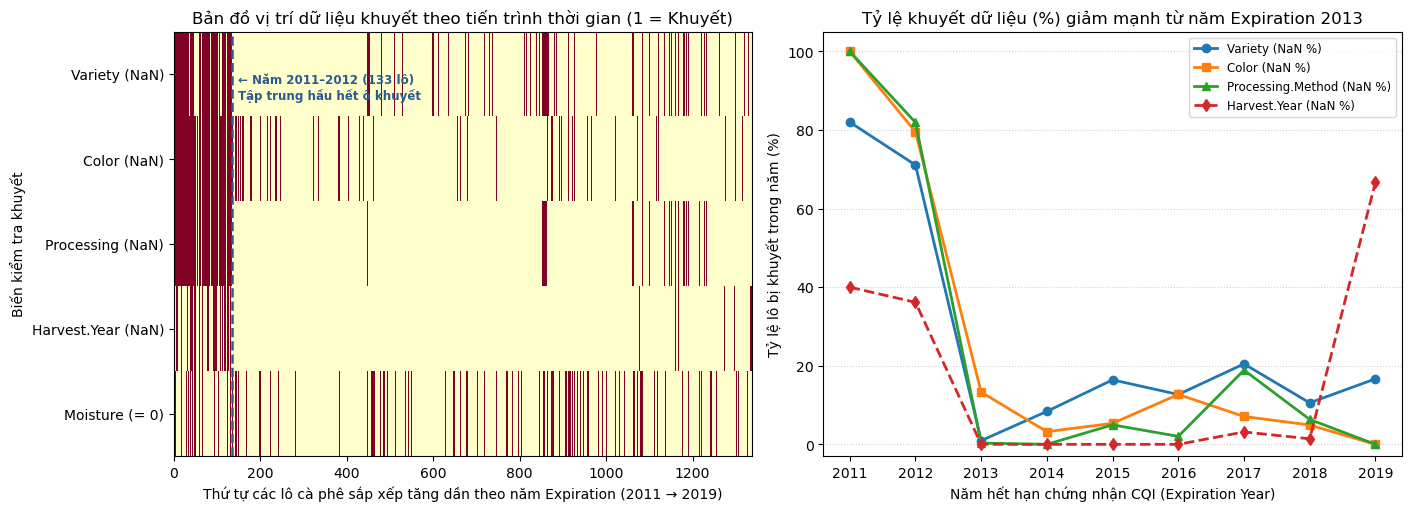

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), layout="constrained")

# Biểu đồ 1: Heatmap vị trí dữ liệu khuyết (gồm cả Moisture==0) sắp xếp theo năm Expiration
ax = axes[0]
sorted_df = df_miss_check.sort_values(["exp_year", "REC_ID"]).reset_index(drop=True)
heatmap_data = pd.DataFrame({
    "Variety (NaN)": sorted_df["Variety"].isna().astype(int),
    "Color (NaN)": sorted_df["Color"].isna().astype(int),
    "Processing (NaN)": sorted_df["Processing.Method"].isna().astype(int),
    "Harvest.Year (NaN)": sorted_df["Harvest.Year"].isna().astype(int),
    "Moisture (= 0)": (sorted_df["Moisture"] == 0).astype(int),
})
im = ax.imshow(heatmap_data.T, aspect="auto", cmap="YlOrRd", interpolation="nearest")
ax.set_yticks(range(len(heatmap_data.columns)), heatmap_data.columns)
ax.set_xlabel("Thứ tự các lô cà phê sắp xếp tăng dần theo năm Expiration (2011 → 2019)")
ax.set_ylabel("Biến kiểm tra khuyết")
ax.set_title("Bản đồ vị trí dữ liệu khuyết theo tiến trình thời gian (1 = Khuyết)")

# Đánh dấu ranh giới năm 2012 -> 2013 trên trục X
n_2011_2012 = int((sorted_df["exp_year"] <= 2012).sum())
ax.axvline(n_2011_2012, color="#2B5C8F", linestyle="--", linewidth=1.8)
ax.text(n_2011_2012 + 15, 0.3, f"← Năm 2011–2012 ({n_2011_2012} lô)\nTập trung hầu hết ô khuyết", color="#2B5C8F", fontweight="bold", fontsize=8.5)

# Biểu đồ 2: Đường xu hướng tỷ lệ khuyết (%) theo năm Expiration
ax = axes[1]
years_plot = by_exp_year.index.astype(str)
ax.plot(years_plot, by_exp_year["Variety_miss_pct"], marker="o", linewidth=2, label="Variety (NaN %)")
ax.plot(years_plot, by_exp_year["Color_miss_pct"], marker="s", linewidth=2, label="Color (NaN %)")
ax.plot(years_plot, by_exp_year["Processing_miss_pct"], marker="^", linewidth=2, label="Processing.Method (NaN %)")
ax.plot(years_plot, by_exp_year["HarvestYear_miss_pct"], marker="d", linewidth=2, linestyle="--", label="Harvest.Year (NaN %)")
ax.set_title("Tỷ lệ khuyết dữ liệu (%) giảm mạnh từ năm Expiration 2013")
ax.set_xlabel("Năm hết hạn chứng nhận CQI (Expiration Year)")
ax.set_ylabel("Tỷ lệ lô bị khuyết trong năm (%)")
ax.set_ylim(-3, 105)
ax.grid(axis="y", linestyle=":", alpha=0.6)
ax.legend(fontsize=8.5)

plt.show()

#### <span style="color:#3B5BA9">d. Kế hoạch xử lý dữ liệu thiếu</span>

<div style="background-color:#FFF7E6;border:1px solid #E8A33D;border-left:6px solid #E8A33D;border-radius:6px;padding:10px 18px;margin:10px 0;font-size:15.5px;line-height:1.65">

<b style="color:#9A5B00;letter-spacing:1px">VÌ SAO KHÔNG XOÁ HẾT DÒNG THIẾU?</b>

Dữ liệu thiếu **không ngẫu nhiên** (MAR theo năm và châu lục). Xoá mọi dòng có `NaN` mất **345/1.339 lô (25,77%)**, gần hết dữ liệu 2010–2011; điền `mode` / `mean` toàn cục cũng gây thiên lệch.

</div>

<div style="font-size:15.5px;line-height:1.65">

| Biến | Mức thiếu | Cách xử lý |
|:---|:---|:---|
| **`REC_ID = 1310`** | 1 lô, 9 điểm = 0 | Loại khỏi mọi phân tích điểm → `df_eda` còn 1.338 lô |
| **Country &amp; Continent** | 1 lô (`REC_ID = 1197`, 0,07%), thiếu cả 6 cột | Giữ khi mô tả toàn mẫu; loại khi phân tích theo xuất xứ (Q1, Q4, Q5, Q6) |
| **`Harvest.Year`** | 60 lô (4,48%); 50/60 ở 2011–2012 | **Q2, Q4, Q5:** loại (không suy từ `Expiration` vì lệch 1–3 năm) · **Q1, Q3, Q6:** giữ |
| **`Processing.Method`** | 170 lô (12,70%); 100% ở 2011, 81,9% ở 2012; châu Phi 20,37% | **Q1:** chỉ lô có nhãn + kiểm tra theo châu lục · **Crosstab, Q2:** nhãn `Unknown` |
| **`Variety`** | 226 lô (16,88%); châu Phi 29,01% | Nhãn `Unknown` (trong `Pipeline` cho Q2); không xoá dòng |
| **`Color`** | 218 `NaN` (16,28%) + 52 `"None"` (3,88%) | Giữ `NaN` là trạng thái thiếu riêng, `"none"` là nhãn; xử lý trong `Pipeline` |
| **`Moisture = 0`** | 264 lô (19,73%) | **Q3:** coi là `NaN` + kiểm tra độ bền (D6) · **Q2:** cờ `moisture_is_zero` hoặc `NaN` → median imputer fit trên train |

</div>

In [52]:
# TEST — Kiểm tra tính chính xác của mục 3.2.4 Missing data
assert int(df.isna().any(axis=1).sum()) == 345, "Phải có đúng 345 dòng thiếu ít nhất 1 cột trên df gốc"
assert int((~df.isna().any(axis=1)).sum()) == 994, "Phải có đúng 994 dòng đầy đủ cả 22 cột"
assert int(df["Country.of.Origin"].isna().sum()) == 1, "Chỉ có 1 dòng thiếu Country.of.Origin (REC_ID=1197)"
assert int(df["Continent.of.Origin"].isna().sum()) == 1, "Chỉ có 1 dòng thiếu Continent.of.Origin (REC_ID=1197)"
assert by_exp_year.loc[2011, "Processing_miss_pct"] == 100.0, "Năm Expiration 2011 thiếu 100% Processing.Method"
assert by_exp_year.loc[2011, "Color_miss_pct"] == 100.0, "Năm Expiration 2011 thiếu 100% Color"
print("Missing data checks passed")

Missing data checks passed


<table style="width:100%;border-collapse:separate;border-spacing:8px 0"><tr><td style="background-color:#EEF3FB;border:1px solid #C9D6EE;border-radius:8px;padding:10px 14px;text-align:center;width:25%"><div style="font-size:24px;font-weight:700;color:#283E75">345</div><div style="font-size:13px;color:#4A5568">lô thiếu ≥ 1 cột (25,77%)</div></td><td style="background-color:#EEF3FB;border:1px solid #C9D6EE;border-radius:8px;padding:10px 14px;text-align:center;width:25%"><div style="font-size:24px;font-weight:700;color:#283E75">994</div><div style="font-size:13px;color:#4A5568">lô đầy đủ (74,23%)</div></td><td style="background-color:#EEF3FB;border:1px solid #C9D6EE;border-radius:8px;padding:10px 14px;text-align:center;width:25%"><div style="font-size:24px;font-weight:700;color:#283E75">6 / 22</div><div style="font-size:13px;color:#4A5568">cột có NaN</div></td><td style="background-color:#EEF3FB;border:1px solid #C9D6EE;border-radius:8px;padding:10px 14px;text-align:center;width:25%"><div style="font-size:24px;font-weight:700;color:#283E75">102</div><div style="font-size:13px;color:#4A5568">lô thiếu cùng lúc 3 cột</div></td></tr></table>

<div style="background-color:#EEF3FB;border:1px solid #283E75;border-left:6px solid #283E75;border-radius:6px;padding:10px 18px;margin:10px 0;font-size:15.5px;line-height:1.65">

<b style="color:#283E75;letter-spacing:1px">NHẬN XÉT: MISSING DATA</b>

- **Cột thiếu nhiều nhất:** `Variety` 226 · `Color` 218 · `Processing.Method` 170 · `Harvest.Year` 60 · `Country` / `Continent` 1 (`REC_ID = 1197`).
- **Thiếu theo cụm:** 102 lô thiếu cùng lúc `Variety + Color + Processing.Method`. Nhóm thiếu `Color` / `Harvest.Year` có tỷ lệ `Moisture = 0` là **38,33–39,45%**, gấp hơn 2 lần nhóm đủ thông tin (15,89–18,86%).
- **Theo thời gian:** 50 lô hết hạn năm 2011 thiếu **100%** `Color` và `Processing.Method`, 82,0% `Variety`, 40,0% `Harvest.Year`; năm 2012 (83 lô) 4 cột này vẫn thiếu 36,1–81,9%. Từ 2013 giảm mạnh ⇒ do **thay đổi biểu mẫu lưu trữ của CQI**.
- **Theo châu lục:** châu Phi thiếu `Variety` 29,01%, `Processing.Method` 20,37% so với Bắc Mỹ 10,09% và 8,58%.
- ⇒ Điền `mode` sẽ gán sai hàng loạt lô châu Phi / Nam Mỹ / 2011–2012 → dùng **`Unknown`** + lọc có kiểm soát theo từng câu hỏi.

</div>

### <span style="color:#283E75">▍3.2.5 · Relationships</span>

#### <span style="color:#3B5BA9">Mẫu phân tích và <code>total_9</code></span>

<div style="font-size:15.5px;line-height:1.65">

`df_eda` = `df` + `total_9`, bỏ `REC_ID = 1310` → **1.338 lô** (cả Arabica và Robusta; vẫn giữ 721 / 742 và các outlier). `total_9` = tổng 9 thuộc tính (thang 0–90); thiếu 1 thuộc tính thì tổng cũng thiếu.

</div>

In [53]:
df_eda = add_total_score(df).loc[lambda rows: rows["REC_ID"].ne(1310)].copy()
physical_cols = ["Moisture", "Quakers", "Category.One.Defects", "Category.Two.Defects"]
relationship_cols = [*SCORE_COLS, *physical_cols, "total_9"]
print(f"Số lô trước và sau khi lọc: {len(df):,} → {len(df_eda):,}")
display_centered_table(df_eda["Species"].value_counts(dropna=False).rename_axis("Species").reset_index(name="n_lots").rename(columns={"n_lots": "Number of coffee lots"}))
display_centered_table(pd.DataFrame({
    "missing": df_eda[physical_cols].isna().sum(),
    "zero": df_eda[physical_cols].eq(0).sum(),
}).rename_axis("variable").reset_index())

Số lô trước và sau khi lọc: 1,339 → 1,338


,Species,Number of coffee lots
0,Arabica,1310
1,Robusta,28


,variable,missing,zero
0,Moisture,0,264
1,Quakers,0,1244
2,Category.One.Defects,0,1136
3,Category.Two.Defects,0,373


#### <span style="color:#3B5BA9">Correlation heatmap và scatter plot</span>

<span style="color:#5B6B8C;font-size:14px">Pearson + Spearman theo từng cặp; <code>pairwise_n</code> là mẫu số. <code>total_9</code> chứa các điểm thành phần nên tương quan với chúng một phần do công thức.</span>

,Aroma,Flavor,Aftertaste,Acidity,Body,Balance,Uniformity,Clean.Cup,Sweetness,Moisture,Quakers,Category.One.Defects,Category.Two.Defects,total_9
Aroma,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338
Flavor,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338
Aftertaste,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338
Acidity,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338
Body,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338
Balance,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338
Uniformity,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338
Clean.Cup,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338
Sweetness,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338
Moisture,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338


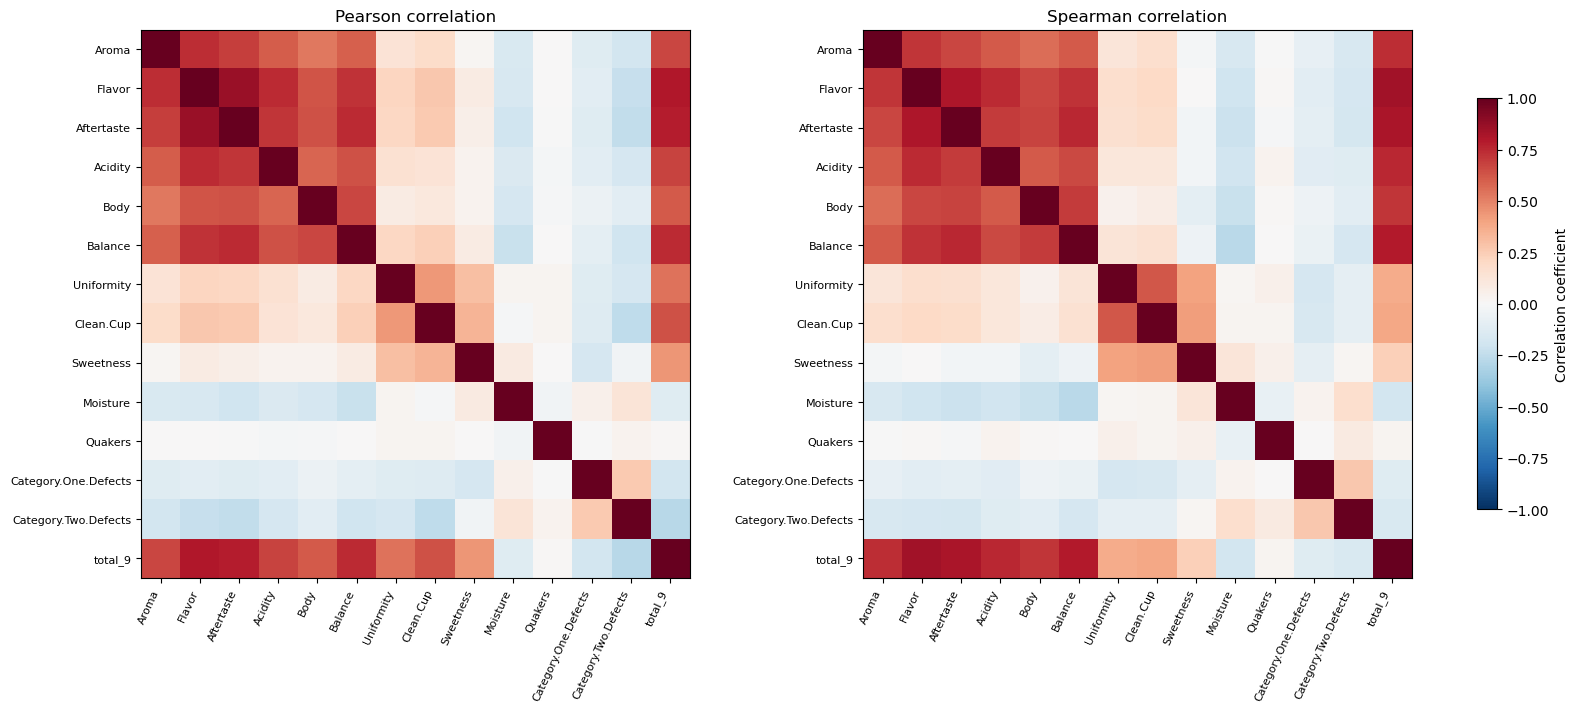

,variable_1,variable_2,Number of coffee lots,pearson,spearman
13,Flavor,Aftertaste,1338,0.860,0.809
24,Flavor,total_9,1338,0.798,0.836
35,Aftertaste,total_9,1338,0.784,0.815
14,Flavor,Acidity,1338,0.746,0.744
27,Aftertaste,Balance,1338,0.746,0.753
62,Balance,total_9,1338,0.743,0.791
0,Aroma,Flavor,1338,0.740,0.715
16,Flavor,Balance,1338,0.720,0.725
25,Aftertaste,Acidity,1338,0.716,0.697
1,Aroma,Aftertaste,1338,0.694,0.668


In [54]:
relationship_numeric = df_eda[relationship_cols]
available = relationship_numeric.notna().astype(int)
pairwise_n = available.T @ available
correlations = {
    method: relationship_numeric.corr(method=method)
    for method in ("pearson", "spearman")
}
display_centered_table(pairwise_n)

fig, axes = plt.subplots(1, 2, figsize=(16, 7), layout="constrained")
for ax, (method, matrix) in zip(axes, correlations.items()):
    image = ax.imshow(matrix, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(matrix)), matrix.columns, rotation=65, ha="right", fontsize=8)
    ax.set_yticks(range(len(matrix)), matrix.index, fontsize=8)
    ax.set_title(f"{method.title()} correlation")
fig.colorbar(image, ax=axes, shrink=0.75, label="Correlation coefficient")
plt.show()

row_idx, col_idx = np.triu_indices(len(relationship_cols), k=1)
correlation_pairs = pd.DataFrame({
    "variable_1": relationship_numeric.columns[row_idx],
    "variable_2": relationship_numeric.columns[col_idx],
    "n_lots": pairwise_n.to_numpy()[row_idx, col_idx],
    **{method: matrix.to_numpy()[row_idx, col_idx] for method, matrix in correlations.items()},
})
display_centered_table(correlation_pairs.sort_values("pearson", key=lambda values: values.abs(), ascending=False).head(10).round(3).rename(columns={"n_lots": "Number of coffee lots"}))

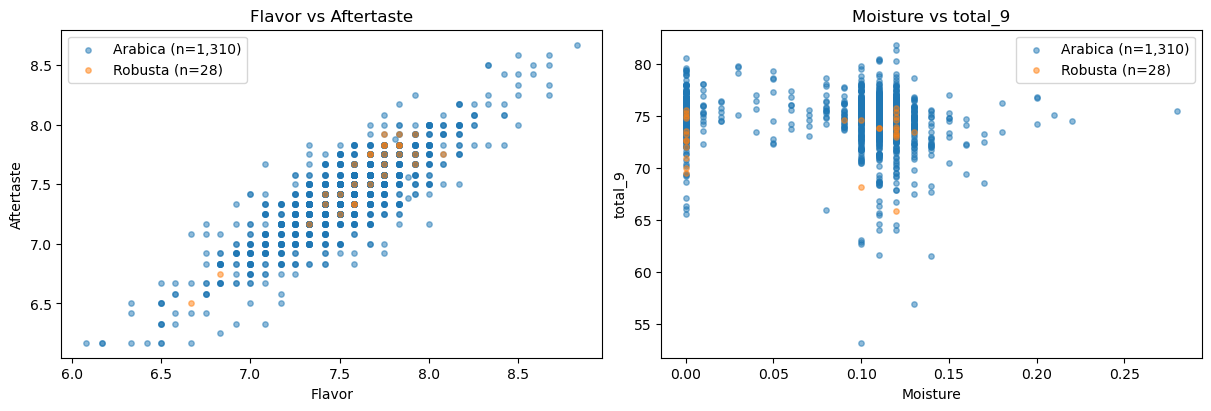

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for ax, (x, y) in zip(axes, [("Flavor", "Aftertaste"), ("Moisture", "total_9")]):
    for species, rows in df_eda.groupby("Species"):
        points = rows[[x, y]].dropna()
        ax.scatter(points[x], points[y], s=15, alpha=0.5, label=f"{species} (n={len(points):,})")
    ax.set_xlabel(x)
    ax.set_ylabel(y)
    ax.set_title(f"{x} vs {y}")
    ax.legend()
plt.show()

#### <span style="color:#3B5BA9"><code>Species</code> và <code>Country.of.Origin</code></span>

<span style="color:#5B6B8C;font-size:14px">Median <code>total_9</code> theo loài; theo quốc gia (tên chưa gộp) chỉ giữ nước có ≥ 20 lô hợp lệ.</span>

In [56]:
valid_score_lots = df_eda.dropna(subset=["total_9"])
species_score_summary = valid_score_lots.groupby("Species")["total_9"].agg(
    n_lots="size", median_total_9="median",
)
country_score_summary = (
    valid_score_lots.groupby("Country.of.Origin")["total_9"]
    .agg(n_lots="size", median_total_9="median")
    .query("n_lots >= 20")
    .sort_values("median_total_9", ascending=False)
)
display_centered_table(species_score_summary.reset_index().round(2).rename(columns={"n_lots": "Number of coffee lots"}))
display_centered_table(country_score_summary.reset_index().round(2).rename(columns={"n_lots": "Number of coffee lots"}))

,Species,Number of coffee lots,median_total_9
0,Arabica,1310,75.00
1,Robusta,28,73.66


,Country.of.Origin,Number of coffee lots,median_total_9
0,Ethiopia,44,77.25
1,Kenya,25,76.83
2,Colombia,183,75.68
3,Uganda,36,75.55
4,El Salvador,21,75.50
5,Indonesia,20,75.37
6,Costa Rica,51,75.34
7,Thailand,32,75.13
8,Guatemala,181,75.07
9,United States,87,75.00


#### <span style="color:#3B5BA9">Crosstab <code>Continent.of.Origin</code> × <code>Processing.Method</code></span>

<span style="color:#5B6B8C;font-size:14px"><code>Unknown</code> = thiếu nhãn. Tỷ lệ theo hàng chỉ dùng lô đủ cả 2 nhãn; <code>n_known</code> là mẫu số.</span>

In [57]:
continent_col = "Continent.of.Origin"
method_col = "Processing.Method"
crosstab_counts = pd.crosstab(
    df_eda[continent_col].fillna("Unknown"),
    df_eda[method_col].fillna("Unknown"),
    margins=True,
    margins_name="Total",
)
known_processing = df_eda.dropna(subset=[continent_col, method_col])
crosstab_pct = pd.crosstab(
    known_processing[continent_col], known_processing[method_col], normalize="index",
).mul(100)
crosstab_pct.insert(0, "n_known", known_processing.groupby(continent_col).size())
print(f"Số lô đủ cả hai nhãn: {len(known_processing):,}")
display_centered_table(crosstab_counts.rename_axis(columns=None).reset_index())
display_centered_table(crosstab_pct.rename_axis(columns=None).reset_index().round(2))

Số lô đủ cả hai nhãn: 1,169


,Continent.of.Origin,Natural / Dry,Other,Pulped natural / honey,Semi-washed / Semi-pulped,Unknown,Washed / Wet,Total
0,Africa,27,0,0,2,33,100,162
1,Asia,32,17,5,14,25,89,182
2,North America,91,8,2,16,57,490,664
3,Oceania,0,0,0,0,0,1,1
4,South America,108,1,7,24,53,135,328
5,Unknown,0,0,0,0,1,0,1
6,Total,258,26,14,56,169,815,1338


,Continent.of.Origin,n_known,Natural / Dry,Other,Pulped natural / honey,Semi-washed / Semi-pulped,Washed / Wet
0,Africa,129,20.93,0.00,0.00,1.55,77.52
1,Asia,157,20.38,10.83,3.18,8.92,56.69
2,North America,607,14.99,1.32,0.33,2.64,80.72
3,Oceania,1,0.00,0.00,0.00,0.00,100.00
4,South America,275,39.27,0.36,2.55,8.73,49.09


In [58]:
# TEST
assert set(df["REC_ID"]) - set(df_eda["REC_ID"]) == {1310}
assert len(df_eda) == len(df) - 1
assert "total_9" not in df.columns
assert {721, 742}.issubset(set(df_eda["REC_ID"]))
assert df_eda["total_9"].isna().equals(df_eda[SCORE_COLS].isna().any(axis=1))
assert crosstab_counts.loc["Total", "Total"] == len(df_eda)
assert crosstab_pct["n_known"].sum() == len(known_processing)
assert np.allclose(crosstab_pct.drop(columns="n_known").sum(axis=1), 100)
assert country_score_summary["n_lots"].ge(20).all()
print("Relationship checks passed")

Relationship checks passed


<div style="background-color:#EEF3FB;border:1px solid #283E75;border-left:6px solid #283E75;border-radius:6px;padding:10px 18px;margin:10px 0;font-size:15.5px;line-height:1.65">

<b style="color:#283E75;letter-spacing:1px">NHẬN XÉT: RELATIONSHIPS</b>

- **Tương quan** (1.338 lô): `Flavor` – `Aftertaste` mạnh (Pearson **0,860** · Spearman **0,809**). `Clean.Cup` – `total_9` chênh giữa 2 hệ số lớn nhất (~0,251), một phần do công thức tổng.
- **`Moisture` – `total_9`:** âm yếu (Pearson −0,121 · Spearman −0,185); điểm phân tán rộng ở 0,10–0,13. Cụm **264 lô tại 0** có thể làm sai hệ số nếu đó là giá trị thiếu.
- **Species:** median Arabica **75,00** (1.310 lô) vs Robusta **73,66** (28 lô), chênh 1,34 điểm. Robusta quá ít lô → chỉ mang tính mô tả.
- **Crosstab** (1.169 lô đủ nhãn): Washed / Wet chiếm 80,72% ở North America (490/607), 77,52% ở Africa (100/129); Natural / Dry cao nhất ở South America **39,27%** (108/275). Africa thiếu nhãn sơ chế 33/162 lô ⇒ đọc tỷ lệ cùng số lô thiếu.
- **Quốc gia** (16 nước ≥ 20 lô): cao nhất **Ethiopia 77,25** (44 lô), Kenya 76,83 (25 lô); thấp nhất **Nicaragua 73,54** (26 lô). Cỡ mẫu từ 20 (Indonesia) đến 236 (Mexico); chênh lệch có thể do loài / sơ chế ⇒ cần so trong cùng nhóm.

</div>

### <span style="color:#283E75">▍3.2.6 · Summary</span>

<table style="width:100%;border-collapse:separate;border-spacing:8px 0"><tr><td style="background-color:#EEF3FB;border:1px solid #C9D6EE;border-radius:8px;padding:10px 14px;text-align:center;width:20%"><div style="font-size:24px;font-weight:700;color:#283E75">1.339</div><div style="font-size:13px;color:#4A5568">lô × 22 cột</div></td><td style="background-color:#EEF3FB;border:1px solid #C9D6EE;border-radius:8px;padding:10px 14px;text-align:center;width:20%"><div style="font-size:24px;font-weight:700;color:#283E75">1.338</div><div style="font-size:13px;color:#4A5568">lô dùng phân tích điểm</div></td><td style="background-color:#EEF3FB;border:1px solid #C9D6EE;border-radius:8px;padding:10px 14px;text-align:center;width:20%"><div style="font-size:24px;font-weight:700;color:#283E75">97,91%</div><div style="font-size:13px;color:#4A5568">là Arabica</div></td><td style="background-color:#EEF3FB;border:1px solid #C9D6EE;border-radius:8px;padding:10px 14px;text-align:center;width:20%"><div style="font-size:24px;font-weight:700;color:#283E75">25,77%</div><div style="font-size:13px;color:#4A5568">lô thiếu ≥ 1 cột</div></td><td style="background-color:#EEF3FB;border:1px solid #C9D6EE;border-radius:8px;padding:10px 14px;text-align:center;width:20%"><div style="font-size:24px;font-weight:700;color:#283E75">19,73%</div><div style="font-size:13px;color:#4A5568">lô có Moisture = 0</div></td></tr></table>

#### <span style="color:#3B5BA9">a. Năm phát hiện chính</span>

<div style="font-size:15.5px;line-height:1.65">

| # | Phát hiện | Bằng chứng |
|:---:|:---|:---|
| 1 | **Mẫu lệch về Arabica và vài nước** | 97,91% Arabica; Mexico + Colombia + Guatemala = 44,81% · median Robusta 73,66 (28 lô) vs Arabica 75,00 (1.310 lô) |
| 2 | **1 bản ghi toàn 0 + trần điểm** | Bỏ `REC_ID = 1310` → median `total_9` 75,00, IQR 73,82–75,92 · Uniformity / Clean.Cup / Sweetness: 86,10–91,11% đạt 10, IQR = 0 |
| 3 | **`Moisture = 0` làm lệch độ ẩm** | 264/1.338 lô; mean 8,8% (toàn mẫu) vs 11,0% (1.074 lô &gt; 0) · lỗi hạt lệch phải, không nên xoá máy móc |
| 4 | **Thiếu theo cột, thời gian, xuất xứ** | 345 lô (25,77%) · lô hết hạn 2011 thiếu 100% nhãn sơ chế · Africa thiếu 33/162 vs North America 57/664 |
| 5 | **Quan hệ phụ thuộc nhóm** | Flavor – Aftertaste 0,860 · Moisture – `total_9` âm yếu · Washed / Wet 80,72% ở North America, Natural / Dry 39,27% ở South America |

</div>

#### <span style="color:#3B5BA9">b. Kế hoạch tiền xử lý</span>

<div style="font-size:15.5px;line-height:1.65">

| Vấn đề | Cách xử lý |
|:---|:---|
| **Bản ghi &amp; khoá** | Giữ bảng gốc để truy vết `REC_ID`; tách lô 1310 khi phân tích điểm; cặp 721 / 742 giữ ở EDA, không để rơi vào 2 tập train/test khác nhau |
| **Cảm quan &amp; lỗi hạt** | Giữ 9 thuộc tính cho `total_9`; kiểm tra độ nhạy với 6 thuộc tính ít trần điểm; so sánh các ngưỡng IQR thay vì xoá |
| **`Moisture = 0`** | Giữ trong bảng gốc + tạo cờ riêng; đối chiếu mẫu gộp với mẫu `Moisture > 0` |
| **Nhãn thiếu &amp; nhóm hiếm** | `Color = "None"` tách khỏi ô trống; `Unknown` trong bảng đếm; ghi rõ mẫu số; `Other (rare)` chỉ để trình bày |
| **Khoá quốc gia – năm** | Chuẩn hoá tên quốc gia, `Harvest.Year` → `Int64`; nối FAOSTAT bằng nhãn chưa gộp; báo số lô khớp / không khớp |

</div>

#### <span style="color:#3B5BA9">c. Hướng phân tích tiếp theo</span>

<div style="background-color:#ECF7F0;border:1px solid #2E8B57;border-left:6px solid #2E8B57;border-radius:6px;padding:10px 18px;margin:10px 0;font-size:15.5px;line-height:1.65">

<b style="color:#1E6B41;letter-spacing:1px">TỪ EDA ĐẾN CÂU HỎI NGHIÊN CỨU</b>

- **Sơ chế ↔ điểm cảm quan:** so `total_9` giữa các phương pháp, kiểm soát theo xuất xứ / loài.
- **Độ ẩm, lỗi hạt ↔ điểm:** so mẫu `Moisture > 0` với toàn mẫu; đối chiếu các cách lọc lô nhiều lỗi (độ bền kết quả).
- **Sản lượng FAOSTAT ↔ điểm theo quốc gia – năm:** lưu ý nhiều lô dùng chung một giá trị sản lượng; báo số lô mỗi nhóm.
- **Hồ sơ cảm quan ↔ trần điểm:** so 9 thuộc tính với 6 thuộc tính để đo ảnh hưởng của 3 cột trần điểm.

</div>

<div style="background-color:#283E75;color:#ffffff;padding:14px 24px;border-radius:8px;margin-top:24px">

<span style="font-size:17px;font-weight:700;letter-spacing:3px;color:#E3EBFA">THAM KHẢO</span>

## <span style="color:#ffffff">Tài liệu tham khảo</span>

<span style="font-size:15px;color:#DCE6F7">Nguồn dữ liệu, giấy phép và tài liệu chuyên môn</span>

</div>

<div style="font-size:15.5px;line-height:1.65">

[1] RealDealAdamP. *Coffee Quality with Locations of Origin*. Kaggle. https://www.kaggle.com/datasets/adampq/coffee-quality-with-locations-of-origin

[2] Coffee Quality Institute. https://www.coffeeinstitute.org

[3] Creative Commons. *Attribution-ShareAlike 4.0 International (CC BY-SA 4.0)*. https://creativecommons.org/licenses/by-sa/4.0/

[4] J. LeDoux. *coffee-quality-database*. GitHub. https://github.com/jldbc/coffee-quality-database

[5] J. VanderPlas. *Python Data Science Handbook*. O'Reilly, 2016.

[6] D. Volpatto. *Coffee Quality database from CQI*. Kaggle. https://www.kaggle.com/datasets/volpatto/coffee-quality-database-from-cqi

[7] F. Boyar. *Coffee Quality Data (CQI May-2023)*. Kaggle. https://www.kaggle.com/datasets/fatihb/coffee-quality-data-cqi

[8] Specialty Coffee Association. *Protocols &amp; Best Practices*. https://sca.coffee/research/protocols-best-practices

</div>